# Predicción de la intención de compra: notebook de resultados

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante aprendizaje
supervisado.
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.
**Datos:** *Online Shoppers Purchasing Intention Dataset* (UCI #468).

Este notebook reúne, en un solo recorrido, la auditoría del conjunto de datos, la configuración
experimental, las métricas de validación cruzada y evaluación, la reducción de dimensión, el
análisis de variables, la ablación de `SpecialDay`, la sensibilidad a `PageValues`, las
comparaciones pareadas y las figuras generadas por el flujo reproducible.

> **Ejecución:** abra el notebook desde la carpeta `notebooks/` o desde la raíz del proyecto.
> La celda de entrada rechaza cualquier otro directorio y no imprime rutas absolutas.

> **Resultados:** todas las tablas se leen directamente de los CSV y JSON de `resultados/`.
> No hay cifras transcritas en el código. Los comentarios y el texto describen la estructura y
> quedan sujetos a la versión de cada archivo presente al ejecutar. Si falta un archivo, la
> sección correspondiente lo advierte y continúa con las demás.

> **Recalcular:** con `RECALCULAR = False` se cargan los artefactos existentes. Con
> `RECALCULAR = True` se llama a `ejecutar_todo.main()`, que reentrena y regenera los resultados;
> esa ruta puede tardar varios minutos.

## Contenido

1. Descripción del problema y paradigma.
2. Estado del arte verificable.
3. Entrada, manifiesto y trazabilidad.
4. Auditoría y particiones.
5. Configuración y búsqueda por validación cruzada.
6. Métricas de validación cruzada, evaluación por familia y heatmap.
7. Variables y eliminación.
8. Reducción de dimensión.
9. `SpecialDay`: ablación y codificación.
10. Sensibilidad a `PageValues`.
11. Comparaciones pareadas.
12. Figuras generadas.
13. Lectura, limitaciones y archivos leídos.
14. Discusión y conclusiones.

## 1. Descripción del problema y paradigma

El problema es clasificación binaria supervisada: cada fila es una sesión de navegación
descrita por 17 atributos y la etiqueta `Revenue` indica si terminó en compra. La
prevalencia es baja (15,47 %), de modo que la exactitud engaña y se privilegian AP,
ROC-AUC y F1. El objetivo es estimar la probabilidad de compra una vez cerrada la sesión:
`PageValues`, la variable más informativa, se calcula con el resultado de la sesión y no
está disponible antes del cierre. El escenario sin `PageValues` se analiza como prueba de
sensibilidad. Se comparan cinco familias (regresión logística, k-NN, Random Forest, MLP y
SVM) con el preprocesamiento ajustado dentro de cada fold, y la reducción de dimensión se
usa para estudiar si la señal se conserva con menos variables latentes.

## 2. Estado del arte verificable

Los cuatro trabajos revisados usan la misma base de datos y son supervisados. Las cifras se
reportan tal como aparecen en las fuentes y no se reproducen en este notebook; los protocolos
difieren en partición, balanceo y validación, así que no son comparables entre sí.

| Trabajo | Modelos | Balanceo y selección | Métrica reportada |
|---|---|---|---|
| Sakar *et al.* (2019) | MLP, RF, SVM | Sobremuestreo; correlación, información mutua y mRMR | MLP: exactitud 87,24 %, F1 0,86 (módulo de compra) |
| Necula (2023) | LR, árboles, RF, SVM | ADASYN; K-means y PCA | RF: ROC-AUC 0,9777 en validación cruzada; 0,8973 en prueba |
| Satu e Islam (2023) | RF, SVM, árboles, LR | SMOTE, tres escalados; CFS, BFS, GRAE, IGAE | RF: exactitud 92,39 %, F1 0,924 |
| Lin (2025) | SVM, XGBoost, CatBoost, red neuronal | SMOTE, Isolation Forest, filtros de variables | CatBoost: precisión 0,934, recall 0,935, ROC-AUC 0,985 |

La fuente de Sakar es de acceso cerrado y su cifra principal se corrobora en un trabajo que la
cita; el protocolo detallado no pudo verificarse. En Lin, el preprocesamiento se describe antes
de la partición y el artículo no reporta intervalos.

## 3. Entrada, manifiesto y trazabilidad

La entrada comprueba que el directorio actual sea `notebooks/` o la raíz del proyecto, agrega
`src/` al camino de importación y fija `resultados/` como única fuente de datos. No se cambia el
directorio de trabajo ni se imprimen rutas absolutas.

`RECALCULAR` controla el costo: con `False` no se ejecuta ningún entrenamiento; con `True` se
invoca el punto de entrada completo `ejecutar_todo.main()`.

In [1]:
from pathlib import Path
import json
import os
import sys

CWD = Path.cwd().resolve()
if CWD.name.lower() == "notebooks" and (CWD.parent / "src" / "ejecutar_todo.py").is_file():
    RAIZ = CWD.parent
    ORIGEN = "notebooks/"
elif (CWD / "src" / "ejecutar_todo.py").is_file() and (CWD / "data").is_dir():
    RAIZ = CWD
    ORIGEN = "raiz del proyecto"
else:
    raise RuntimeError(
        "Ejecute este notebook desde la carpeta notebooks/ o desde la raiz del proyecto."
    )

if not (RAIZ / "src" / "ejecutar_todo.py").is_file():
    raise RuntimeError("No se encontró src/ejecutar_todo.py desde el directorio de ejecución.")

sys.path.insert(0, str(RAIZ / "src"))
RES = RAIZ / "resultados"
FIG_INFORME = RAIZ / "informe_entregable_II_latex" / "figuras"
FIG_NOTEBOOK = RES / "figuras"
NOTEBOOK_DIR = RAIZ / "notebooks"

RECALCULAR = False  # True para reentrenar y regenerar resultados con ejecutar_todo.main()

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

print("Origen de ejecución:", ORIGEN)
print("Resultados: resultados/")
print("Recalcular con ejecutar_todo.main():", RECALCULAR)

Origen de ejecución: notebooks/
Resultados: resultados/
Recalcular con ejecutar_todo.main(): False


In [2]:
if RECALCULAR:
    import ejecutar_todo
    ejecutar_todo.main()
else:
    print("RECALCULAR=False: se cargan los artefactos existentes; no se reentrena.")

RECALCULAR=False: se cargan los artefactos existentes; no se reentrena.


In [3]:
REGISTRO = []


def _partes(partes):
    return (partes,) if isinstance(partes, str) else tuple(partes)


def _ruta_res(partes):
    return RES.joinpath(*_partes(partes))


def _rel(ruta):
    try:
        return ruta.resolve().relative_to(RAIZ).as_posix()
    except ValueError:
        return ruta.name


def leer_csv(partes, titulo, obligatoria=False, filas=None, orden=None):
    ruta = _ruta_res(partes)
    if not ruta.is_file():
        mensaje = f"AVISO: falta {_rel(ruta)}; se omite la tabla '{titulo}'."
        if obligatoria:
            raise FileNotFoundError(mensaje)
        print(mensaje)
        return None
    try:
        tabla = pd.read_csv(ruta)
    except pd.errors.EmptyDataError:
        print(f"AVISO: {_rel(ruta)} está vacío; se omite la tabla '{titulo}'.")
        return None
    if orden and set(orden).issubset(tabla.columns):
        tabla = tabla.sort_values(orden).reset_index(drop=True)
    REGISTRO.append(
        {"archivo": _rel(ruta), "filas": len(tabla), "columnas": len(tabla.columns)}
    )
    display(
        Markdown(
            f"**{titulo}** (`{_rel(ruta)}`; {len(tabla)} filas x {len(tabla.columns)} columnas)"
        )
    )
    display(tabla if filas is None else tabla.head(filas))
    return tabla


def leer_json(partes, titulo, obligatoria=False):
    ruta = _ruta_res(partes)
    if not ruta.is_file():
        mensaje = f"AVISO: falta {_rel(ruta)}; se omite '{titulo}'."
        if obligatoria:
            raise FileNotFoundError(mensaje)
        print(mensaje)
        return None
    contenido = json.loads(ruta.read_text(encoding="utf-8"))
    REGISTRO.append({"archivo": _rel(ruta), "filas": None, "columnas": None})
    display(Markdown(f"**{titulo}** (`{_rel(ruta)}`)"))
    return contenido


def leer_csv_variantes(variantes, titulo, obligatoria=False, filas=None, orden=None):
    # Carga el primer archivo existente entre varias rutas candidatas.
    # ``variantes`` es una lista de rutas relativas, cada una como tupla de partes.
    candidatos = [tuple(v) for v in variantes]
    for partes in candidatos:
        if _ruta_res(partes).is_file():
            return leer_csv(partes, titulo, obligatoria=obligatoria, filas=filas, orden=orden)
    rutas = ", ".join(_rel(_ruta_res(partes)) for partes in candidatos)
    mensaje = f"AVISO: falta {rutas}; se omite la tabla '{titulo}'."
    if obligatoria:
        raise FileNotFoundError(mensaje)
    print(mensaje)
    return None


def mostrar_json(contenido, titulo=None):
    if contenido is None:
        return
    if titulo:
        display(Markdown(f"**{titulo}**"))
    display(Markdown("```json\n" + json.dumps(contenido, indent=2, ensure_ascii=False) + "\n```"))


def buscar_figura(nombre, carpetas=None):
    for carpeta in (carpetas or (FIG_NOTEBOOK, FIG_INFORME, RES / "figuras_informe")):
        ruta = carpeta / nombre
        if ruta.is_file():
            return ruta
    return None


def mostrar_figura(nombre, titulo=None, carpetas=None):
    ruta = buscar_figura(nombre, carpetas)
    if ruta is None:
        print(
            f"AVISO: no se encontro {nombre} en las carpetas de figuras del flujo "
            "(resultados/figuras, informe_entregable_II_latex/figuras)."
        )
        return False
    display(Markdown(f"**{titulo or ruta.stem}** (`{_rel(ruta)}`)"))
    display(Image(filename=str(ruta)))
    enlace = Path(os.path.relpath(ruta, start=NOTEBOOK_DIR)).as_posix()
    display(Markdown(f"[Abrir figura: {ruta.name}]({enlace})"))
    return True

### 3.1 Manifiesto y cobertura de artefactos

El manifiesto lo escribe `ejecutar_todo.main()` al final de cada ejecución. Si no existe, el
notebook sigue en modo de solo lectura y advierte que los resultados pueden estar incompletos.

In [4]:
manifiesto = leer_json("manifiesto.json", "Manifiesto de la ejecución")
if manifiesto:
    for clave in ("fecha_utc", "sha256_datos", "semilla", "python", "rapido", "desde"):
        if clave in manifiesto:
            print(f"{clave}: {manifiesto[clave]}")
    if isinstance(manifiesto.get("versiones"), dict):
        display(Markdown("**Versiones registradas**"))
        display(
            pd.DataFrame(
                [{"paquete": k, "version": v} for k, v in manifiesto["versiones"].items()]
            )
        )
    if isinstance(manifiesto.get("duracion_etapas_seg"), dict):
        display(Markdown("**Duración por etapa (segundos)**"))
        display(
            pd.DataFrame(
                [{"etapa": k, "segundos": v} for k, v in manifiesto["duracion_etapas_seg"].items()]
            )
        )

REQUERIDOS = [
    "auditoria.json",
    "tabla_variables.csv",
    "resumen_particiones.csv",
    "mejores_configuraciones.csv",
    "ganador.json",
    "evaluacion_familias/metricas.csv",
    "evaluacion_familias/intervalos.csv",
    "evaluacion_familias/cv_intervalos.csv",
    "variables/analisis_variables.csv",
    "specialday_ablacion.csv",
    "comparacion_pagevalues.csv",
    "reduccion/reduccion_test.csv",
]
cobertura = pd.DataFrame(
    [{"archivo": rel, "presente": (RES / rel).is_file()} for rel in REQUERIDOS]
)
display(Markdown("**Cobertura de artefactos principales**"))
display(cobertura)
faltantes = cobertura.loc[~cobertura["presente"], "archivo"].tolist()
if faltantes:
    print("AVISO: faltan artefactos principales; las secciones afectadas se omiten.")
else:
    print("Todos los artefactos principales estan presentes.")

**Manifiesto de la ejecución** (`resultados/manifiesto.json`)

fecha_utc: 2026-11-16T16:32:21.108563+00:00
sha256_datos: d8e130ba51532985f93281a73ce299e6ce150cb915769a7962a11e595eadd6a1
semilla: 42
python: 3.13.5
rapido: False
desde: variables


**Versiones registradas**

,paquete,version
0,numpy,2.3.1
1,pandas,2.3.1
2,scipy,1.16.3
3,scikit-learn,1.7.2
4,matplotlib,3.10.7
5,umap-learn,0.6.0
6,numba,0.68.1


**Duración por etapa (segundos)**

,etapa,segundos
0,datos,0.024
1,figuras,3.984
2,reduccion,3122.196
3,variables,63.405


**Cobertura de artefactos principales**

,archivo,presente
0,auditoria.json,True
1,tabla_variables.csv,True
2,resumen_particiones.csv,True
3,mejores_configuraciones.csv,True
4,ganador.json,True
5,evaluacion_familias/metricas.csv,True
6,evaluacion_familias/intervalos.csv,True
7,evaluacion_familias/cv_intervalos.csv,True
8,variables/analisis_variables.csv,True
9,specialday_ablacion.csv,True


Todos los artefactos principales estan presentes.


## 4. Auditoría y particiones

La auditoría verifica dimensiones, nulos, duplicados exactos, balance de clases y rangos de las
variables. Las particiones son estratificadas 60/20/20 sobre el conjunto sin duplicados exactos.
Los valores mostrados a continuación provienen de `auditoria.json`, `tabla_variables.csv`,
`resumen_particiones.csv` y `cobertura_mensual_train.csv`.

In [5]:
auditoria = leer_json("auditoria.json", "Auditoría del conjunto de datos")
if auditoria:
    claves = [
        "archivo",
        "filas",
        "columnas",
        "nulos_totales",
        "duplicados_exactos",
        "clases",
        "proporcion_compra",
        "valores_especialday",
        "semilla",
        "version_sklearn",
    ]
    filas = []
    for clave in claves:
        if clave in auditoria:
            valor = auditoria[clave]
            if isinstance(valor, (dict, list)):
                valor = json.dumps(valor, ensure_ascii=False)
            filas.append({"campo": clave, "valor": valor})
    display(pd.DataFrame(filas))

tabla_variables = leer_csv("tabla_variables.csv", "Tabla de variables")
resumen_particiones = leer_csv("resumen_particiones.csv", "Resumen de particiones")
cobertura_mensual = leer_csv(
    "cobertura_mensual_train.csv", "Cobertura mensual y tasa de compra en entrenamiento"
)

**Auditoría del conjunto de datos** (`resultados/auditoria.json`)

,campo,valor
0,archivo,online_shoppers_intention.csv
1,filas,12330
2,columnas,18
3,nulos_totales,0
4,duplicados_exactos,125
5,clases,"{""False"": 10422, ""True"": 1908}"
6,proporcion_compra,0.154745
7,valores_especialday,"[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]"
8,semilla,42
9,version_sklearn,1.7.2


**Tabla de variables** (`resultados/tabla_variables.csv`; 18 filas x 9 columnas)

,variable,tipo,n_unicos,min,max,media,nulos,categoria_mas_frecuente,frecuencia_max
0,Administrative,numerica,27,0.0,27.000000,2.315166,0,NaN,NaN
1,Administrative_Duration,numerica,3335,0.0,3398.750000,80.818611,0,NaN,NaN
2,Informational,numerica,17,0.0,24.000000,0.503569,0,NaN,NaN
3,Informational_Duration,numerica,1258,0.0,2549.375000,34.472398,0,NaN,NaN
4,ProductRelated,numerica,311,0.0,705.000000,31.731468,0,NaN,NaN
5,ProductRelated_Duration,numerica,9551,0.0,63973.522230,1194.746220,0,NaN,NaN
6,BounceRates,numerica,1872,0.0,0.200000,0.022191,0,NaN,NaN
7,ExitRates,numerica,4777,0.0,0.200000,0.043073,0,NaN,NaN
8,PageValues,numerica,2704,0.0,361.763742,5.889258,0,NaN,NaN
9,Month,categorica,10,NaN,NaN,NaN,0,May,3364.0


**Resumen de particiones** (`resultados/resumen_particiones.csv`; 3 filas x 5 columnas)

,particion,n,positivos,negativos,proporcion_compra
0,Entrenamiento,7323,1145,6178,0.156357
1,Validacion,2441,381,2060,0.156084
2,Test,2441,382,2059,0.156493


**Cobertura mensual y tasa de compra en entrenamiento** (`resultados/cobertura_mensual_train.csv`; 10 filas x 3 columnas)

,Month,sesiones,tasa_compra
0,Aug,278,0.190647
1,Dec,1017,0.137660
2,Feb,115,0.017391
3,Jul,240,0.137500
4,June,164,0.097561
5,Mar,1159,0.106126
6,May,1981,0.107521
7,Nov,1752,0.251712
8,Oct,343,0.215743
9,Sep,274,0.182482


## 5. Configuración y búsqueda por validación cruzada

`mejores_configuraciones.csv` contiene una configuración seleccionada por familia y
`ganador.json` registra la regla de selección. `validacion_top3.csv` conserva los tres
candidatos por familia que pasaron a validación. La búsqueda completa se muestra resumida:
las primeras filas del CSV y los tres mejores candidatos por familia, sin transcribir valores.

In [6]:
mejores = leer_csv(
    "mejores_configuraciones.csv", "Configuraciones seleccionadas por familia", orden=["modelo"]
)
ganador = leer_json("ganador.json", "Ganador seleccionado en validación")
mostrar_json(ganador)
validacion_top3 = leer_csv("validacion_top3.csv", "Top-3 por familia en validación")
busqueda_cv = leer_csv(
    "cv_todos_los_candidatos.csv", "Búsqueda CV: primeras filas", filas=5
)
if busqueda_cv is not None and {"modelo", "mean_test_score"}.issubset(busqueda_cv.columns):
    columnas = [
        c
        for c in ["modelo", "mean_test_score", "std_test_score", "rank_test_score", "params"]
        if c in busqueda_cv.columns
    ]
    resumen_busqueda = (
        busqueda_cv.sort_values("mean_test_score", ascending=False)
        .groupby("modelo", as_index=False)
        .head(3)[columnas]
        .sort_values(["modelo", "mean_test_score"], ascending=[True, False])
    )
    display(
        Markdown(
            "**Tres mejores candidatos por familia (derivado de `cv_todos_los_candidatos.csv`)**"
        )
    )
    display(resumen_busqueda)

**Configuraciones seleccionadas por familia** (`resultados/mejores_configuraciones.csv`; 5 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041,MLP,3,0.737548,0.034179,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
1,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,3,0.757273,0.023408,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
2,0.684086,0.912316,0.717042,0.585302,0.644509,0.771292,0.899222,Regresion_logistica,1,0.689679,0.031968,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
3,0.705417,0.900071,0.701299,0.566929,0.626996,0.761134,0.894715,SVM,2,0.725999,0.035145,"{'clf__C': 30, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."
4,0.701831,0.912418,0.726562,0.488189,0.583987,0.727104,0.891438,kNN,3,0.717198,0.023194,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"


**Ganador seleccionado en validación** (`resultados/ganador.json`)

```json
{
  "modelo": "RandomForest",
  "criterio": "mayor AP en validacion entre top-3 por AP-CV de cada familia; la prueba no participa",
  "AP_validacion": 0.7414039953316898,
  "params": "{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'pre__num__log__usar_log': True}"
}
```

**Top-3 por familia en validación** (`resultados/validacion_top3.csv`; 15 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.684086,0.912316,0.717042,0.585302,0.644509,0.771292,0.899222,Regresion_logistica,1,0.689679,0.031968,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
1,0.680827,0.911904,0.710191,0.585302,0.641727,0.770564,0.897993,Regresion_logistica,2,0.687614,0.031661,"{'clf__C': 1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
2,0.679020,0.910793,0.707937,0.585302,0.640805,0.770321,0.897583,Regresion_logistica,3,0.686270,0.031252,"{'clf__C': 10, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
3,0.696642,0.909811,0.716912,0.511811,0.597243,0.737216,0.892257,kNN,1,0.720316,0.026245,"{'clf__n_neighbors': 61, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
4,0.692758,0.907432,0.715356,0.501312,0.589506,0.732210,0.891028,kNN,2,0.717979,0.027087,"{'clf__n_neighbors': 45, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
5,0.701831,0.912418,0.726562,0.488189,0.583987,0.727104,0.891438,kNN,3,0.717198,0.023194,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
6,0.735217,0.926179,0.730000,0.574803,0.643172,0.767741,0.900451,RandomForest,1,0.759074,0.030828,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 5, 'pr..."
7,0.739210,0.926545,0.713376,0.587927,0.644604,0.772119,0.898812,RandomForest,2,0.757421,0.027015,"{'clf__class_weight': None, 'clf__max_depth': 6, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 10, 'p..."
8,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,3,0.757273,0.023408,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
9,0.711947,0.918709,0.696078,0.559055,0.620087,0.756955,0.893077,MLP,1,0.741916,0.033361,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log__u..."


**Búsqueda CV: primeras filas** (`resultados/cv_todos_los_candidatos.csv`; 730 filas x 36 columnas)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__C,param_clf__class_weight,param_pre__num__log__usar_log,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score,modelo,tiempo_total_seg,param_clf__n_neighbors,param_clf__p,param_clf__weights,param_clf__max_depth,param_clf__max_features,param_clf__min_samples_leaf,param_clf__alpha,param_clf__hidden_layer_sizes,param_clf__learning_rate_init,param_clf__kernel,param_clf__gamma
0,0.207022,0.077596,0.035643,0.016551,0.01,NaN,True,"{'clf__C': 0.01, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.632742,0.712383,0.684342,0.680399,0.711212,0.684216,0.028936,5,0.702270,0.682729,0.689955,0.688716,0.677116,0.688157,0.008416,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.182681,0.056351,0.038141,0.010850,0.01,NaN,False,"{'clf__C': 0.01, 'clf__class_weight': None, 'pre__num__log__usar_log': False}",0.587808,0.667443,0.640996,0.633335,0.679487,0.641814,0.031829,15,0.658328,0.639656,0.651437,0.646809,0.636107,0.646468,0.007990,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.232384,0.080325,0.046336,0.008690,0.01,balanced,True,"{'clf__C': 0.01, 'clf__class_weight': 'balanced', 'pre__num__log__usar_log': True}",0.617702,0.706897,0.674009,0.665493,0.688952,0.670611,0.029967,7,0.687636,0.664651,0.673995,0.674732,0.663142,0.672831,0.008774,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.214948,0.062957,0.041929,0.022682,0.01,balanced,False,"{'clf__C': 0.01, 'clf__class_weight': 'balanced', 'pre__num__log__usar_log': False}",0.587916,0.670738,0.636965,0.634171,0.678560,0.641670,0.032167,16,0.657626,0.639577,0.650024,0.646235,0.635548,0.645802,0.007768,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.213815,0.081960,0.032141,0.006303,0.10,NaN,True,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.628899,0.712408,0.692277,0.695921,0.718890,0.689679,0.031968,1,0.715374,0.697364,0.699949,0.698919,0.690060,0.700333,0.008279,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Tres mejores candidatos por familia (derivado de `cv_todos_los_candidatos.csv`)**

,modelo,mean_test_score,std_test_score,rank_test_score,params
528,MLP,0.741916,0.033361,1,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log__u..."
428,MLP,0.738180,0.031251,2,"{'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log_..."
570,MLP,0.737548,0.034179,3,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
125,RandomForest,0.759074,0.030828,1,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 5, 'pr..."
110,RandomForest,0.757421,0.027015,2,"{'clf__class_weight': None, 'clf__max_depth': 6, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 10, 'p..."
135,RandomForest,0.757273,0.023408,3,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
4,Regresion_logistica,0.689679,0.031968,1,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
8,Regresion_logistica,0.687614,0.031661,2,"{'clf__C': 1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
12,Regresion_logistica,0.686270,0.031252,3,"{'clf__C': 10, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
674,SVM,0.726585,0.033579,1,"{'clf__C': 10, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."


### 5.1 Mallas de hiperparámetros

Las mallas se definen en `shopytics/search.py` y la etapa `busqueda` registra cada combinación en
`combinaciones_malla.csv`. La tabla siguiente resume los valores explorados por familia y el
total evaluado.

In [7]:
from shopytics.search import mallas_ampliadas

mallas_md = []
for familia, mallas_familia in mallas_ampliadas()[1].items():
    bloques = mallas_familia if isinstance(mallas_familia, list) else [mallas_familia]
    valores = []
    for malla in bloques:
        for clave, opciones in malla.items():
            nombre = clave.replace("clf__", "").replace("pre__", "")
            valores.append(f"{nombre}: {', '.join(str(o) for o in opciones)}")
    mallas_md.append({"familia": familia, "bloques": len(bloques),
                      "valores": " | ".join(valores)})
display(pd.DataFrame(mallas_md))

combinaciones = leer_csv("combinaciones_malla.csv", "Combinaciones evaluadas")
if combinaciones is not None:
    display(combinaciones)
    print("Total de combinaciones: " + str(int(combinaciones["combinaciones"].sum())))

,familia,bloques,valores
0,Regresion_logistica,1,"num__log__usar_log: True, False | C: 0.01, 0.1, 1, 10, 100 | class_weight: None, balanced"
1,kNN,1,"num__log__usar_log: True, False | n_neighbors: 5, 15, 31, 45, 61, 81, 101 | weights: uniform, distance | p..."
2,RandomForest,1,"num__log__usar_log: True | max_depth: 4, 6, 8, 10, 12, 20, None | max_features: log2, sqrt, 0.3, 0.5, 0.7 ..."
3,MLP,1,"num__log__usar_log: True, False | hidden_layer_sizes: (32,), (64,), (128,), (64, 32), (128, 64) | alpha: 1..."
4,SVM,2,"num__log__usar_log: True, False | kernel: linear | C: 0.01, 0.03, 0.1, 1, 10, 100 | class_weight: None, ba..."


**Combinaciones evaluadas** (`resultados/combinaciones_malla.csv`; 5 filas x 2 columnas)

,modelo,combinaciones
0,Regresion_logistica,20
1,kNN,56
2,RandomForest,280
3,MLP,250
4,SVM,124


,modelo,combinaciones
0,Regresion_logistica,20
1,kNN,56
2,RandomForest,280
3,MLP,250
4,SVM,124


Total de combinaciones: 730


## 6. Métricas CV, evaluación por familia y heatmap

La validación cruzada se ejecuta solo sobre entrenamiento con cinco folds estratificados. La
evaluación final compara las cinco familias en entrenamiento, validación y prueba, con intervalos
bootstrap condicionales a los modelos ya fijados. El heatmap resume el AP por modelo y partición
sin sustituir las tablas.

In [8]:
cv_intervalos = leer_csv(
    ("evaluacion_familias", "cv_intervalos.csv"),
    "Intervalos de validación cruzada en entrenamiento",
    orden=["metrica", "media"],
)
metricas = leer_csv(
    ("evaluacion_familias", "metricas.csv"), "Métricas por familia y partición"
)
if metricas is not None and {"modelo", "particion"}.issubset(metricas.columns):
    columnas = [
        c
        for c in [
            "modelo",
            "particion",
            "AP",
            "ROC_AUC",
            "F1",
            "precision",
            "recall",
            "balanced_accuracy",
            "accuracy",
        ]
        if c in metricas.columns
    ]
    display(Markdown("**Vista ordenada de métricas por familia y partición**"))
    display(metricas[columnas].sort_values(["modelo", "particion"]).round(4))

intervalos = leer_csv(
    ("evaluacion_familias", "intervalos.csv"), "Intervalos bootstrap por partición"
)
if intervalos is not None and {"metrica", "particion"}.issubset(intervalos.columns):
    ap = intervalos[intervalos["metrica"].astype(str).str.upper() == "AP"]
    if not ap.empty:
        display(Markdown("**AP con intervalo bootstrap del 95 %**"))
        display(ap.sort_values(["modelo", "particion"]).round(4))

umbrales = leer_csv(
    ("evaluacion_familias", "umbrales.csv"), "Umbrales F1 elegidos en validación"
)
metricas_umbral = leer_csv(
    ("evaluacion_familias", "metricas_test_umbral.csv"),
    "Métricas de prueba con el umbral F1 de validación",
)
resumen_evaluacion = leer_json(
    ("evaluacion_familias", "resumen.json"), "Resumen de la evaluación"
)
mostrar_json(resumen_evaluacion)

**Intervalos de validación cruzada en entrenamiento** (`resultados/evaluacion_familias/cv_intervalos.csv`; 15 filas x 8 columnas)

,modelo,metrica,n_folds,media,desviacion,error_estandar,ic_inferior,ic_superior
0,Regresion_logistica,AP,5,0.689679,0.035742,0.015984,0.645300,0.734058
1,kNN,AP,5,0.717198,0.025932,0.011597,0.684999,0.749397
2,SVM,AP,5,0.725999,0.039294,0.017573,0.677209,0.774788
3,MLP,AP,5,0.737548,0.038213,0.017089,0.690100,0.784995
4,RandomForest,AP,5,0.757273,0.026171,0.011704,0.724777,0.789768
5,kNN,F1,5,0.576026,0.051471,0.023018,0.512117,0.639935
6,Regresion_logistica,F1,5,0.616411,0.029675,0.013271,0.579564,0.653258
7,MLP,F1,5,0.639059,0.055470,0.024807,0.570184,0.707933
8,SVM,F1,5,0.657975,0.049793,0.022268,0.596149,0.719801
9,RandomForest,F1,5,0.664919,0.034251,0.015318,0.622391,0.707448


**Métricas por familia y partición** (`resultados/evaluacion_familias/metricas.csv`; 15 filas x 9 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,particion
0,0.828421,0.957273,0.797657,0.654148,0.718810,0.811697,0.919978,RandomForest,entrenamiento
1,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,validacion
2,0.749559,0.930164,0.744262,0.594241,0.660844,0.778179,0.904547,RandomForest,test
3,0.779798,0.942947,0.750000,0.634061,0.687175,0.797445,0.909736,MLP,entrenamiento
4,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041,MLP,validacion
5,0.749373,0.928356,0.715655,0.586387,0.644604,0.771581,0.898812,MLP,test
6,0.798594,0.938647,0.774530,0.648035,0.705659,0.806536,0.915472,SVM,entrenamiento
7,0.705417,0.900071,0.701299,0.566929,0.626996,0.761134,0.894715,SVM,validacion
8,0.727191,0.903411,0.721003,0.602094,0.656205,0.779435,0.901270,SVM,test
9,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,kNN,entrenamiento


**Vista ordenada de métricas por familia y partición**

,modelo,particion,AP,ROC_AUC,F1,precision,recall,balanced_accuracy,accuracy
3,MLP,entrenamiento,0.7798,0.9429,0.6872,0.7500,0.6341,0.7974,0.9097
5,MLP,test,0.7494,0.9284,0.6446,0.7157,0.5864,0.7716,0.8988
4,MLP,validacion,0.7225,0.9242,0.6504,0.7161,0.5958,0.7761,0.9000
0,RandomForest,entrenamiento,0.8284,0.9573,0.7188,0.7977,0.6541,0.8117,0.9200
2,RandomForest,test,0.7496,0.9302,0.6608,0.7443,0.5942,0.7782,0.9045
1,RandomForest,validacion,0.7414,0.9265,0.6370,0.7025,0.5827,0.7685,0.8964
12,Regresion_logistica,entrenamiento,0.6987,0.9194,0.6227,0.7141,0.5520,0.7555,0.8954
14,Regresion_logistica,test,0.6956,0.9110,0.6213,0.7143,0.5497,0.7545,0.8951
13,Regresion_logistica,validacion,0.6841,0.9123,0.6445,0.7170,0.5853,0.7713,0.8992
6,SVM,entrenamiento,0.7986,0.9386,0.7057,0.7745,0.6480,0.8065,0.9155


... (6 outputs left out)

**Métricas de prueba con el umbral F1 de validación** (`resultados/evaluacion_familias/metricas_test_umbral.csv`; 5 filas x 10 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,particion,umbral
0,0.749559,0.930164,0.650463,0.735602,0.690418,0.831133,0.896764,RandomForest,test,0.319528
1,0.749373,0.928356,0.681818,0.667539,0.674603,0.804872,0.899222,MLP,test,0.433714
2,0.727191,0.903411,0.634483,0.722513,0.675643,0.822646,0.891438,SVM,test,-0.697044
3,0.697556,0.907502,0.654696,0.620419,0.637097,0.779855,0.889390,kNN,test,0.398862
4,0.695633,0.910977,0.633735,0.688482,0.659975,0.807330,0.888980,Regresion_logistica,test,0.317197


**Resumen de la evaluación** (`resultados/evaluacion_familias/resumen.json`)

```json
{
  "ganador_validacion": "RandomForest",
  "AP_validacion": {
    "RandomForest": 0.7414039953316898,
    "MLP": 0.7224787231125073,
    "SVM": 0.7054172967034158,
    "kNN": 0.7018307073794038,
    "Regresion_logistica": 0.6840864664961273
  },
  "n_boot": 2000,
  "semilla": 42,
  "cv": {
    "n_folds": 5,
    "particion": "entrenamiento",
    "intervalo": "t de Student al 95% con desviacion muestral"
  },
  "bootstrap": "estratificado pareado, condicionado a puntuaciones fijas",
  "limitacion_prueba": "La particion de prueba fue consultada en el analisis historico.",
  "ablaciones": {
    "sin_pagevalues": {
      "AP_validacion": 0.3784866913236957,
      "delta_AP": 0.36291730400799405
    },
    "sin_specialday": {
      "AP_validacion": 0.7417741592117094,
      "delta_AP": -0.0003701638800196472
    }
  }
}
```

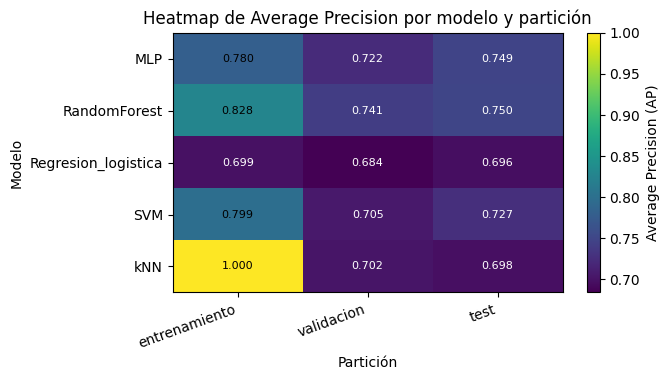

In [9]:
if metricas is not None and {"modelo", "particion", "AP"}.issubset(metricas.columns):
    import matplotlib.pyplot as plt
    import numpy as np

    pivote = metricas.pivot_table(
        index="modelo", columns="particion", values="AP", aggfunc="mean"
    )
    orden = [p for p in ("entrenamiento", "validacion", "test") if p in pivote.columns]
    if orden:
        pivote = pivote[orden]
    datos = pivote.to_numpy(dtype=float)
    fig, eje = plt.subplots(figsize=(6.8, 3.9))
    imagen = eje.imshow(datos, cmap="viridis", aspect="auto")
    eje.set_xticks(range(len(pivote.columns)))
    eje.set_xticklabels([str(c) for c in pivote.columns], rotation=20, ha="right")
    eje.set_yticks(range(len(pivote.index)))
    eje.set_yticklabels([str(i) for i in pivote.index])
    eje.set_xlabel("Partición")
    eje.set_ylabel("Modelo")
    eje.set_title("Heatmap de Average Precision por modelo y partición")
    limite = np.nanmean(datos) if np.isfinite(datos).any() else 0.0
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            valor = datos[i, j]
            texto = f"{valor:.3f}" if np.isfinite(valor) else "NA"
            eje.text(
                j,
                i,
                texto,
                ha="center",
                va="center",
                color="white" if valor < limite else "black",
                fontsize=8,
            )
    fig.colorbar(imagen, ax=eje, label="Average Precision (AP)")
    fig.tight_layout()
    plt.show()
else:
    print("AVISO: no hay tabla de métricas para construir el heatmap.")

## 7. Variables y eliminación

El análisis descriptivo usa solo entrenamiento: correlación punto-biserial o V de Cramer, AUC
univariado e información mutua. La eliminación compara las configuraciones de Random Forest y
MLP con todas las variables, sin las candidatas de menor AUC y sin las numéricas redundantes.
La prueba no participa en estas decisiones.

In [10]:
analisis_variables = leer_csv(
    ("variables", "analisis_variables.csv"), "Análisis univariado de variables"
)
redundancia = leer_csv(
    ("variables", "redundancia_numericas.csv"),
    "Pares de variables numéricas con correlación absoluta >= 0.8",
)
eliminacion_validacion = leer_csv(
    ("variables", "eliminacion_validacion.csv"),
    "Eliminación de variables: resultados en validación",
)
eliminacion_cv = leer_csv(
    ("variables", "eliminacion_cv.csv"), "Eliminación de variables: validación cruzada"
)
resumen_eliminacion = leer_json(
    ("variables", "eliminacion_resumen.json"), "Resumen de eliminación de variables"
)
if resumen_eliminacion:
    claves = [
        "candidatas",
        "criterio_candidatas",
        "n_folds",
        "n_entrenamiento",
        "n_validacion",
        "prueba",
    ]
    mostrar_json(
        {k: resumen_eliminacion[k] for k in claves if k in resumen_eliminacion},
        "Protocolo de eliminación",
    )

**Análisis univariado de variables** (`resultados/variables/analisis_variables.csv`; 17 filas x 11 columnas)

,variable,tipo,metrica,valor,p_valor,auc_univariado,direccion,informacion_mutua,indice_fisher,ranking,recomendacion
0,PageValues,numérica,correlación punto-biserial,0.488849,0.000000e+00,0.866362,positiva,0.165087,0.477511,1,mantener
1,ExitRates,numérica,correlación punto-biserial,-0.210426,4.434559e-74,0.710126,negativa,0.042920,0.275206,2,mantener
2,ProductRelated_Duration,numérica,correlación punto-biserial,0.141842,3.197950e-34,0.668875,positiva,0.031664,0.070239,3,mantener
3,ProductRelated,numérica,correlación punto-biserial,0.156095,3.626287e-41,0.658200,positiva,0.029647,0.074029,4,mantener
4,Administrative,numérica,correlación punto-biserial,0.132891,3.292128e-30,0.625789,positiva,0.015745,0.062171,5,mantener
5,TrafficType,categórica,V de Cramér,0.177351,NaN,0.625124,positiva,0.016062,NaN,6,mantener
6,Administrative_Duration,numérica,correlación punto-biserial,0.075871,7.985450e-11,0.620179,positiva,0.013561,0.021748,7,mantener
7,Month,categórica,V de Cramér,0.171862,NaN,0.615963,positiva,0.014715,NaN,8,mantener
8,BounceRates,numérica,correlación punto-biserial,-0.147691,5.467656e-37,0.612409,negativa,0.026788,0.137678,9,mantener
9,Informational,numérica,correlación punto-biserial,0.089650,1.519148e-14,0.557870,positiva,0.006738,0.025835,10,revisar


**Pares de variables numéricas con correlación absoluta >= 0.8** (`resultados/variables/redundancia_numericas.csv`; 2 filas x 3 columnas)

,variable_1,variable_2,correlacion
0,ProductRelated,ProductRelated_Duration,0.842609
1,BounceRates,ExitRates,0.898962


**Eliminación de variables: resultados en validación** (`resultados/variables/eliminacion_validacion.csv`; 6 filas x 12 columnas)

,modelo,variante,excluidas,AP_CV,std_CV,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy
0,RandomForest,completo,NaN,0.757273,0.023408,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354
1,RandomForest,sin_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay;OperatingSystems,0.756609,0.024917,0.742205,0.927278,0.701258,0.585302,0.638054,0.769593,0.896354
2,RandomForest,sin_redundantes,ProductRelated_Duration;BounceRates,0.748463,0.026756,0.734773,0.927299,0.705329,0.590551,0.642857,0.772460,0.897583
3,MLP,completo,NaN,0.737548,0.034179,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041
4,MLP,sin_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay;OperatingSystems,0.741343,0.026771,0.741430,0.928260,0.695652,0.629921,0.661157,0.789475,0.899222
5,MLP,sin_redundantes,ProductRelated_Duration;BounceRates,0.735852,0.032524,0.725033,0.919244,0.724590,0.580052,0.644315,0.769638,0.900041


**Eliminación de variables: validación cruzada** (`resultados/variables/eliminacion_cv.csv`; 6 filas x 6 columnas)

,modelo,variante,excluidas,AP_CV,std_CV,AP_folds
0,RandomForest,completo,NaN,0.757273,0.023408,"[0.7175583526632671, 0.745449251473784, 0.7717370907554228, 0.7678669071913788, 0.7837527009915638]"
1,RandomForest,sin_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay;OperatingSystems,0.756609,0.024917,"[0.7142761295362977, 0.7436950127234714, 0.771179278764857, 0.7696697740981441, 0.7842252546982804]"
2,RandomForest,sin_redundantes,ProductRelated_Duration;BounceRates,0.748463,0.026756,"[0.7080889014003262, 0.7252638628877954, 0.7650218103565047, 0.7679949557378642, 0.7759474643065052]"
3,MLP,completo,NaN,0.737548,0.034179,"[0.6812683498038121, 0.7172874545388145, 0.7557240936350351, 0.777443767478738, 0.7560139969030542]"
4,MLP,sin_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay;OperatingSystems,0.741343,0.026771,"[0.694738526647194, 0.7284813397097825, 0.7554017154296484, 0.7670029883957742, 0.7610898197227273]"
5,MLP,sin_redundantes,ProductRelated_Duration;BounceRates,0.735852,0.032524,"[0.6799119381059874, 0.7198345114565242, 0.7495597948007591, 0.7680233182541689, 0.7619323633159214]"


**Resumen de eliminación de variables** (`resultados/variables/eliminacion_resumen.json`)

**Protocolo de eliminación**

```json
{
  "candidatas": [
    "Weekend",
    "Region",
    "Browser",
    "VisitorType",
    "SpecialDay",
    "OperatingSystems"
  ],
  "criterio_candidatas": "variables con AUC univariado menor que 0.55, derivadas del propio analisis (recomendacion 'eliminar o combinar')",
  "n_folds": 5,
  "n_entrenamiento": 7323,
  "n_validacion": 2441,
  "prueba": "no participa en el analisis ni en la eliminacion"
}
```

## 8. Reducción de dimensión

La reducción se ajusta dentro del `Pipeline`, solo con entrenamiento. El barrido PCA y UMAP se
evalúa por validación cruzada y validación; la prueba se consulta después de fijar las variantes.
Las tablas siguientes leen `reduccion_cv.csv`, `reduccion_validacion.csv`,
`reduccion_test.csv`, `pca_varianza.csv`, `pca_barrido.csv`, `umap_barrido.csv`,
`reduccion_comparacion.csv` y `reduccion_protocolo.json`. Los intervalos bootstrap por variante
viajan como columnas de `reduccion_test.csv`.

In [11]:
reduccion_cv = leer_csv(("reduccion", "reduccion_cv.csv"), "Reducción: validación cruzada")
reduccion_validacion = leer_csv(
    ("reduccion", "reduccion_validacion.csv"), "Reducción: resultados en validación"
)
reduccion_test = leer_csv(
    ("reduccion", "reduccion_test.csv"), "Reducción: resultados en prueba"
)
if reduccion_test is not None:
    columnas_ic = [
        c
        for c in [
            "modelo",
            "metodo",
            "componentes",
            "AP",
            "media_bootstrap_AP",
            "ic_AP_inferior",
            "ic_AP_superior",
            "ROC_AUC",
            "media_bootstrap_ROC_AUC",
            "ic_ROC_AUC_inferior",
            "ic_ROC_AUC_superior",
        ]
        if c in reduccion_test.columns
    ]
    if len(columnas_ic) > 2:
        display(Markdown("**Prueba por variante con intervalos bootstrap por columna**"))
        display(reduccion_test[columnas_ic].round(4))
pca_varianza = leer_csv(
    ("reduccion", "pca_varianza.csv"), "PCA: primeras filas de varianza acumulada", filas=8
)
if pca_varianza is not None and {
    "modelo",
    "componente",
    "varianza_acumulada",
}.issubset(pca_varianza.columns):
    n95 = (
        pca_varianza[pca_varianza["varianza_acumulada"] >= 0.95]
        .sort_values(["modelo", "componente"])
        .groupby("modelo", as_index=False)
        .head(1)
    )
    display(
        Markdown(
            "**Primer componente que alcanza el 95 % de varianza acumulada (por modelo)**"
        )
    )
    display(n95[["modelo", "componente", "varianza_acumulada"]].round(5))

pca_barrido = leer_csv(
    ("reduccion", "pca_barrido.csv"), "PCA: barrido de componentes"
)
umap_barrido = leer_csv(
    ("reduccion", "umap_barrido.csv"), "UMAP: barrido de dimensiones y vecinos"
)
reduccion_comparaciones = leer_csv(
    ("reduccion", "reduccion_comparacion.csv"),
    "Reducción: diferencias pareadas contra la base en prueba",
)
protocolo_reduccion = leer_json(
    ("reduccion", "reduccion_protocolo.json"), "Protocolo de reducción"
)
if protocolo_reduccion:
    seleccion = protocolo_reduccion.get("seleccion")
    if seleccion:
        display(Markdown("**Variantes seleccionadas por validación**"))
        display(pd.DataFrame(seleccion).round(4))
    claves = ["n_folds", "n_boot", "regla_simplicidad", "limitacion", "prueba"]
    resumen_protocolo = {k: protocolo_reduccion[k] for k in claves if k in protocolo_reduccion}
    if resumen_protocolo:
        mostrar_json(resumen_protocolo, "Resumen del protocolo de reducción")

if reduccion_test is not None:
    resumen_reduccion = reduccion_test.copy()
    resumen_reduccion["reduccion_pct"] = (1 - resumen_reduccion["componentes"] / 73) * 100
    columnas_resumen = [
        c for c in ["modelo", "metodo", "componentes", "reduccion_pct", "AP",
                    "ic_AP_inferior", "ic_AP_superior", "ROC_AUC", "F1"]
        if c in resumen_reduccion.columns
    ]
    display(
        Markdown("**Resumen de reducción: componentes, porcentaje y métricas de prueba**")
    )
    display(resumen_reduccion[columnas_resumen].round(4))

**Reducción: validación cruzada** (`resultados/reduccion/reduccion_cv.csv`; 46 filas x 9 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_folds,finalista
0,RandomForest,PCA,5.00,NaN,5,0.702170,0.025421,"[0.671328901850622, 0.6849038375849495, 0.6991296257433192, 0.7095142723667371, 0.7459737810279176]",True
1,RandomForest,PCA,10.00,NaN,10,0.719798,0.031735,"[0.6661472859833788, 0.7058433925204257, 0.7310246894785951, 0.7368788128225421, 0.7590980443306466]",True
2,RandomForest,PCA,15.00,NaN,15,0.728921,0.033953,"[0.669243078765772, 0.7167954667796406, 0.739957424461386, 0.7526893425791941, 0.7659186732163904]",True
3,RandomForest,PCA,20.00,NaN,20,0.728808,0.033740,"[0.6679989247524891, 0.718799678603015, 0.7424289499085206, 0.75136830881523, 0.7634431103626591]",True
4,RandomForest,PCA,28.00,NaN,28,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",True
5,RandomForest,PCA,35.00,NaN,35,0.726616,0.033392,"[0.6674201741549863, 0.7152102749459163, 0.7372239362457101, 0.7528290384257272, 0.7603967648872407]",True
6,RandomForest,PCA,45.00,NaN,45,0.724961,0.031144,"[0.6727379683953515, 0.7075683634014925, 0.7380035338316633, 0.7482660069572488, 0.7582286816432887]",True
7,RandomForest,PCA,0.95,NaN,28,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",True
8,RandomForest,UMAP,2.00,15.0,2,0.678690,0.027392,"[0.6399247486299001, 0.666414991558648, 0.6782954473834483, 0.6847192949003411, 0.7240964509787594]",True
9,RandomForest,UMAP,2.00,30.0,2,0.678839,0.031355,"[0.6289122824569696, 0.6712869065094977, 0.695435972169605, 0.6742328974579073, 0.7243271513208707]",True


**Reducción: resultados en validación** (`resultados/reduccion/reduccion_validacion.csv`; 50 filas x 24 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_folds,varianza_acumulada,seleccionado,motivo_seleccion,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,AP_max_validacion,desviacion_std_CV,n_folds,error_estandar_CV,umbral_simplicidad,diferencia_con_max
0,RandomForest,Base,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,referencia_sin_reduccion,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,NaN,NaN,NaN,NaN,NaN,NaN
1,RandomForest,PCA,5.00,NaN,5.0,0.702170,0.025421,"[0.671328901850622, 0.6849038375849495, 0.6991296257433192, 0.7095142723667371, 0.7459737810279176]",0.656386,False,NaN,0.693642,0.906501,0.687697,0.572178,0.624642,0.762060,0.892667,NaN,NaN,NaN,NaN,NaN,NaN
2,RandomForest,PCA,10.00,NaN,10.0,0.719798,0.031735,"[0.6661472859833788, 0.7058433925204257, 0.7310246894785951, 0.7368788128225421, 0.7590980443306466]",0.803802,True,simplicidad,0.707384,0.905127,0.693811,0.559055,0.619186,0.756712,0.892667,0.718395,0.031144,5.0,0.013928,0.704467,0.011011
3,RandomForest,PCA,15.00,NaN,15.0,0.728921,0.033953,"[0.669243078765772, 0.7167954667796406, 0.739957424461386, 0.7526893425791941, 0.7659186732163904]",0.868771,False,NaN,0.715540,0.914253,0.693009,0.598425,0.642254,0.774698,0.895944,NaN,NaN,NaN,NaN,NaN,NaN
4,RandomForest,PCA,20.00,NaN,20.0,0.728808,0.033740,"[0.6679989247524891, 0.718799678603015, 0.7424289499085206, 0.75136830881523, 0.7634431103626591]",0.911908,False,NaN,0.714437,0.913651,0.700617,0.595801,0.643972,0.774357,0.897173,NaN,NaN,NaN,NaN,NaN,NaN
5,RandomForest,PCA,28.00,NaN,28.0,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",0.953367,False,NaN,0.716483,0.915381,0.699387,0.598425,0.644979,0.775426,0.897173,NaN,NaN,NaN,NaN,NaN,NaN
6,RandomForest,PCA,35.00,NaN,35.0,0.726616,0.033392,"[0.6674201741549863, 0.7152102749459163, 0.7372239362457101, 0.7528290384257272, 0.7603967648872407]",0.975638,False,NaN,0.716433,0.915507,0.703704,0.598425,0.646809,0.775912,0.897993,NaN,NaN,NaN,NaN,NaN,NaN
7,RandomForest,PCA,45.00,NaN,45.0,0.724961,0.031144,"[0.6727379683953515, 0.7075683634014925, 0.7380035338316633, 0.7482660069572488, 0.7582286816432887]",0.994005,False,NaN,0.718395,0.917059,0.700906,0.608924,0.651685,0.780433,0.898402,NaN,NaN,NaN,NaN,NaN,NaN
8,RandomForest,PCA,0.95,NaN,28.0,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",0.953367,False,NaN,0.716483,0.915381,0.699387,0.598425,0.644979,0.775426,0.897173,NaN,NaN,NaN,NaN,NaN,NaN
9,RandomForest,UMAP,2.00,15.0,2.0,0.678690,0.027392,"[0.6399247486299001, 0.666414991558648, 0.6782954473834483, 0.6847192949003411, 0.7240964509787594]",NaN,False,NaN,0.653088,0.891500,0.658273,0.480315,0.555387,0.717099,0.879967,NaN,NaN,NaN,NaN,NaN,NaN


**Reducción: resultados en prueba** (`resultados/reduccion/reduccion_test.csv`; 8 filas x 38 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_validacion,varianza_acumulada,n_boot,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,media_bootstrap_AP,ic_AP_inferior,ic_AP_superior,media_bootstrap_ROC_AUC,ic_ROC_AUC_inferior,ic_ROC_AUC_superior,media_bootstrap_precision,ic_precision_inferior,ic_precision_superior,media_bootstrap_recall,ic_recall_inferior,ic_recall_superior,media_bootstrap_F1,ic_F1_inferior,ic_F1_superior,media_bootstrap_balanced_accuracy,ic_balanced_accuracy_inferior,ic_balanced_accuracy_superior,media_bootstrap_accuracy,ic_accuracy_inferior,ic_accuracy_superior
0,RandomForest,PCA,10.0,NaN,10.0,0.719798,0.031735,0.707384,0.803802,2000,0.723557,0.913445,0.705085,0.544503,0.614476,0.751125,0.893077,0.724492,0.683123,0.762615,0.913700,0.898148,0.928478,0.706369,0.660430,0.750866,0.543890,0.494764,0.594241,0.614257,0.573939,0.654973,0.750935,0.726498,0.775468,0.893178,0.882425,0.903318
1,RandomForest,UMAP,15.0,50.0,15.0,0.697988,0.021588,0.695895,NaN,2000,0.687948,0.893632,0.706522,0.510471,0.592705,0.735566,0.890209,0.689164,0.647793,0.729206,0.893949,0.875827,0.911022,0.707328,0.658532,0.757579,0.510611,0.460733,0.560209,0.592756,0.547770,0.636098,0.735674,0.710452,0.761219,0.890295,0.879558,0.900451
2,RandomForest,UMAP2D,2.0,15.0,2.0,NaN,NaN,0.653088,NaN,2000,0.659540,0.888349,0.656934,0.471204,0.548780,0.712775,0.878738,0.660829,0.618995,0.701904,0.888661,0.869618,0.905917,0.657787,0.607140,0.708819,0.470652,0.418848,0.520942,0.548383,0.502339,0.593796,0.712580,0.686445,0.737857,0.878787,0.868087,0.889799
3,RandomForest,Base,NaN,NaN,NaN,NaN,NaN,0.741404,NaN,2000,0.749559,0.930164,0.744262,0.594241,0.660844,0.778179,0.904547,0.750543,0.713407,0.786883,0.930434,0.917772,0.942950,0.744684,0.700641,0.788599,0.594101,0.544503,0.641361,0.660620,0.621097,0.698370,0.778117,0.753401,0.801647,0.904538,0.894715,0.914379
4,MLP,PCA,15.0,NaN,15.0,0.736776,0.039131,0.721903,0.868771,2000,0.740809,0.925491,0.762590,0.554974,0.642424,0.761460,0.903318,0.742030,0.702662,0.780295,0.925820,0.912804,0.938906,0.763836,0.715950,0.810227,0.554619,0.505236,0.604712,0.642294,0.600939,0.683582,0.761369,0.737127,0.786817,0.903410,0.893486,0.913150
5,MLP,UMAP,5.0,30.0,5.0,0.673880,0.021275,0.648414,NaN,2000,0.638077,0.862019,0.682609,0.410995,0.513072,0.687770,0.877919,0.639507,0.596013,0.683001,0.862243,0.840202,0.883235,0.683790,0.628349,0.736406,0.411058,0.361257,0.463351,0.513077,0.465430,0.561517,0.687870,0.663416,0.714346,0.878044,0.867677,0.888161
6,MLP,UMAP2D,2.0,15.0,2.0,NaN,NaN,0.604236,NaN,2000,0.581463,0.852172,0.640411,0.489529,0.554896,0.719267,0.877100,0.585484,0.536582,0.637002,0.852647,0.829106,0.874631,0.641592,0.594933,0.690765,0.489280,0.439725,0.539267,0.554863,0.508977,0.597668,0.719251,0.693709,0.744627,0.877244,0.866448,0.888161
7,MLP,Base,NaN,NaN,NaN,NaN,NaN,0.722479,NaN,2000,0.749373,0.928356,0.715655,0.586387,0.644604,0.771581,0.898812,0.750369,0.712699,0.787315,0.928557,0.914971,0.940975,0.716630,0.671510,0.761294,0.585965,0.539202,0.636126,0.644447,0.604046,0.683763,0.771448,0.747481,0.796169,0.898878,0.888161,0.909463


... (15 outputs left out)

**Resumen del protocolo de reducción**

```json
{
  "n_folds": 5,
  "n_boot": 2000,
  "regla_simplicidad": {
    "criterio": "regla 1-SE: se parte del mayor AP de validacion; una variante mas simple lo sustituye si su AP_validacion >= AP_max - std_CV/sqrt(n_folds) del ganador",
    "desviacion": "std_CV poblacional entre folds del candidato con mayor AP de validacion; un valor no finito se trata como 0",
    "error_estandar": "std_CV / sqrt(n_folds), con n_folds leido de AP_folds del ganador (5 en la corrida completa)",
    "frontera": "la igualdad cuenta como dentro del umbral (diferencia <= error estandar); con std_CV=0 solo los empates exactos activan la simplicidad",
    "complejidad_umap": "solo el numero de componentes; los vecinos no cuentan como complejidad",
    "complejidad_pca": "menor numero de componentes ajustado; a igualdad, valor fijo antes que 0.95",
    "desempate": "entre las candidatas elegibles de menor dimension gana la de mayor AP de validacion",
    "empates": "orden determinista por la clave de simplicidad y luego por el orden de la rejilla"
  },
  "limitacion": "la particion de prueba fue consultada historicamente; los IC son condicionales a las variantes fijadas",
  "prueba": "test se consulta solo despues de fijar todas las variantes; no participa en la seleccion"
}
```

**Resumen de reducción: componentes, porcentaje y métricas de prueba**

,modelo,metodo,componentes,reduccion_pct,AP,ic_AP_inferior,ic_AP_superior,ROC_AUC,F1
0,RandomForest,PCA,10.0,86.3014,0.7236,0.6831,0.7626,0.9134,0.6145
1,RandomForest,UMAP,15.0,79.4521,0.6879,0.6478,0.7292,0.8936,0.5927
2,RandomForest,UMAP2D,2.0,97.2603,0.6595,0.6190,0.7019,0.8883,0.5488
3,RandomForest,Base,NaN,NaN,0.7496,0.7134,0.7869,0.9302,0.6608
4,MLP,PCA,15.0,79.4521,0.7408,0.7027,0.7803,0.9255,0.6424
5,MLP,UMAP,5.0,93.1507,0.6381,0.5960,0.6830,0.8620,0.5131
6,MLP,UMAP2D,2.0,97.2603,0.5815,0.5366,0.6370,0.8522,0.5549
7,MLP,Base,NaN,NaN,0.7494,0.7127,0.7873,0.9284,0.6446


## 9. SpecialDay

La ablación compara, por familia, el AP de validación con y sin `SpecialDay`. La comparación de
codificación contrasta la columna numérica con one-hot de seis niveles. La tabla por mes es
opcional y solo usa validación. Los resultados se leen de `specialday_ablacion.csv`,
`specialday_codificacion.csv` y `specialday_por_mes.csv`.

In [12]:
ablacion_specialday = leer_csv(
    "specialday_ablacion.csv", "SpecialDay: ablación por familia"
)
codificacion_specialday = leer_csv(
    "specialday_codificacion.csv", "SpecialDay: comparación de codificación"
)
por_mes_specialday = leer_csv(
    "specialday_por_mes.csv", "SpecialDay: AP del ganador por mes de validación"
)

**SpecialDay: ablación por familia** (`resultados/specialday_ablacion.csv`; 5 filas x 5 columnas)

,modelo,AP_con_SpecialDay,AP_sin_SpecialDay,delta_AP_con_menos_sin,params
0,Regresion_logistica,0.684086,0.684458,-0.000372,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
1,kNN,0.701831,0.706630,-0.004799,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
2,RandomForest,0.741404,0.741774,-0.000370,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
3,MLP,0.722479,0.718074,0.004405,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
4,SVM,0.705417,0.704042,0.001375,"{'clf__C': 30, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."


**SpecialDay: comparación de codificación** (`resultados/specialday_codificacion.csv`; 5 filas x 13 columnas)

,modelo,AP_CV_numerico,std_CV_numerico,AP_CV_onehot,std_CV_onehot,delta_AP_CV_onehot_menos_numerico,AP_validacion_numerico,AP_validacion_onehot,delta_AP_validacion_onehot_menos_numerico,n_columnas_numerico,n_columnas_onehot,folds_numerico,folds_onehot
0,Regresion_logistica,0.689679,0.031968,0.690747,0.032692,0.001068,0.684086,0.683523,-0.000564,73,78,"[0.6288985682674647, 0.712407614417046, 0.6922771935312317, 0.6959213147616863, 0.7188901809450964]","[0.6281863220926237, 0.7137966115830792, 0.6942044597074853, 0.6978926488447172, 0.7196569974407684]"
1,kNN,0.717198,0.023194,0.721572,0.025380,0.004374,0.701831,0.706456,0.004625,73,78,"[0.6864034333248556, 0.706059637835591, 0.7160910369435487, 0.7201429050748082, 0.7572926171212431]","[0.6845618592974622, 0.708283186475248, 0.7209779025130185, 0.7332550066553486, 0.7607834062665132]"
2,RandomForest,0.757273,0.023408,0.755575,0.024264,-0.001698,0.741404,0.741774,0.000370,73,78,"[0.7175583526632671, 0.745449251473784, 0.7717370907554228, 0.7678669071913788, 0.7837527009915638]","[0.7148890159904973, 0.7413412328031802, 0.7734222994829939, 0.7677812205358824, 0.7804418493078288]"
3,MLP,0.737548,0.034179,0.736536,0.037293,-0.001012,0.722479,0.732152,0.009673,73,78,"[0.6812683498038121, 0.7172874545388145, 0.7557240936350351, 0.777443767478738, 0.7560139969030542]","[0.6708131670760575, 0.7199232444583861, 0.757252495399496, 0.771271803007029, 0.7634168135048687]"
4,SVM,0.725999,0.035145,0.728743,0.035359,0.002745,0.705417,0.698814,-0.006603,73,78,"[0.6702588831723362, 0.7040586796569613, 0.7385689319175782, 0.7461005887993346, 0.77100564312203]","[0.6697263199193544, 0.7093310654244187, 0.7447307451015286, 0.7503104842290673, 0.7696169462637175]"


**SpecialDay: AP del ganador por mes de validación** (`resultados/specialday_por_mes.csv`; 10 filas x 5 columnas)

,modelo,mes,n,positivos,AP_validacion
0,RandomForest,Feb,37,0,NaN
1,RandomForest,Mar,359,38,0.785284
2,RandomForest,May,663,74,0.876918
3,RandomForest,June,58,7,0.690011
4,RandomForest,Jul,96,15,0.598316
5,RandomForest,Aug,76,8,0.567959
6,RandomForest,Sep,87,17,0.838979
7,RandomForest,Oct,98,15,0.589077
8,RandomForest,Nov,633,166,0.682606
9,RandomForest,Dec,334,41,0.766951


## 10. Sensibilidad a PageValues

La sensibilidad repite la selección de las cinco familias sin `PageValues`, con la misma malla y
la misma regla top-3. La comparación principal y las configuraciones sin esa variable se leen de
`comparacion_pagevalues.csv` y `mejores_sin_pagevalues.csv`.

In [13]:
comparacion_pagevalues = leer_csv(
    "comparacion_pagevalues.csv", "Sensibilidad: comparación con y sin PageValues"
)
mejores_sin_pagevalues = leer_csv(
    "mejores_sin_pagevalues.csv", "Mejores configuraciones sin PageValues"
)

**Sensibilidad: comparación con y sin PageValues** (`resultados/comparacion_pagevalues.csv`; 5 filas x 7 columnas)

,modelo,AP_con,ROC_AUC_con,AP_sin,ROC_AUC_sin,params,delta_AP
0,RandomForest,0.741404,0.926500,0.384824,0.784684,"{'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_l...",0.356580
1,MLP,0.722479,0.924230,0.353228,0.765268,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.01, 'pre__num__log__usa...",0.369250
2,SVM,0.705417,0.900071,0.340259,0.768538,"{'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__u...",0.365158
3,kNN,0.701831,0.912418,0.347742,0.761518,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}",0.354089
4,Regresion_logistica,0.684086,0.912316,0.334490,0.761583,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.349597


**Mejores configuraciones sin PageValues** (`resultados/mejores_sin_pagevalues.csv`; 5 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.384824,0.784684,0.384289,0.475066,0.424883,0.667144,0.799263,RandomForest,1,0.388310,0.036455,"{'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_l..."
1,0.353228,0.765268,0.470588,0.041995,0.077108,0.516628,0.843097,MLP,3,0.358650,0.032075,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.01, 'pre__num__log__usa..."
2,0.347742,0.761518,0.000000,0.000000,0.000000,0.499757,0.843507,kNN,2,0.336228,0.019433,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
3,0.340259,0.768538,0.259041,0.808399,0.392357,0.690365,0.609177,SVM,2,0.342799,0.020540,"{'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__u..."
4,0.334490,0.761583,0.285714,0.015748,0.029851,0.504233,0.840229,Regresion_logistica,1,0.349300,0.022576,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"


## 11. Comparaciones pareadas

Las comparaciones de evaluación usan bootstrap pareado sobre las puntuaciones de prueba para AP
y ROC-AUC. Las de reducción comparan las variantes fijadas. Se muestran las tablas completas y,
por separado, las filas cuyo intervalo del 95 % excluye cero; esa separacion es una lectura
descriptiva y no convierte los intervalos en una prueba independiente.

In [14]:
comparaciones_evaluacion = leer_csv_variantes(
    [
        ("evaluacion_familias", "comparaciones_test.csv"),
    ],
    "Comparaciones pareadas de evaluación en prueba",
)

if comparaciones_evaluacion is not None and {
    "ic_inferior",
    "ic_superior",
}.issubset(comparaciones_evaluacion.columns):
    significativas = comparaciones_evaluacion[
        (comparaciones_evaluacion["ic_inferior"] > 0)
        | (comparaciones_evaluacion["ic_superior"] < 0)
    ].copy()
    display(
        Markdown(
            f"**Intervalos que excluyen cero: {len(significativas)} de "
            f"{len(comparaciones_evaluacion)} filas**"
        )
    )
    display(significativas.round(4))

if reduccion_comparaciones is not None and {
    "ic_inferior",
    "ic_superior",
}.issubset(reduccion_comparaciones.columns):
    significativas_red = reduccion_comparaciones[
        (reduccion_comparaciones["ic_inferior"] > 0)
        | (reduccion_comparaciones["ic_superior"] < 0)
    ].copy()
    display(
        Markdown(
            f"**Reducción: intervalos que excluyen cero: {len(significativas_red)} de "
            f"{len(reduccion_comparaciones)} filas**"
        )
    )
    display(significativas_red.round(4))

**Comparaciones pareadas de evaluación en prueba** (`resultados/evaluacion_familias/comparaciones_test.csv`; 20 filas x 8 columnas)

,modelo_a,modelo_b,metrica,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
0,RandomForest,MLP,AP,0.000186,0.000174,-0.019023,0.019046,2000
1,RandomForest,MLP,ROC_AUC,0.001808,0.001878,-0.003550,0.007505,2000
2,RandomForest,SVM,AP,0.022368,0.022310,0.000105,0.044985,2000
3,RandomForest,SVM,ROC_AUC,0.026753,0.026965,0.014360,0.040621,2000
4,RandomForest,kNN,AP,0.052004,0.051549,0.030420,0.073651,2000
5,RandomForest,kNN,ROC_AUC,0.022662,0.022563,0.015115,0.030681,2000
6,RandomForest,Regresion_logistica,AP,0.053926,0.053073,0.024366,0.081249,2000
7,RandomForest,Regresion_logistica,ROC_AUC,0.019187,0.019103,0.010694,0.028877,2000
8,MLP,SVM,AP,0.022182,0.022137,0.006788,0.037929,2000
9,MLP,SVM,ROC_AUC,0.024945,0.025087,0.013010,0.038172,2000


**Intervalos que excluyen cero: 14 de 20 filas**

,modelo_a,modelo_b,metrica,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
2,RandomForest,SVM,AP,0.0224,0.0223,0.0001,0.0450,2000
3,RandomForest,SVM,ROC_AUC,0.0268,0.0270,0.0144,0.0406,2000
4,RandomForest,kNN,AP,0.0520,0.0515,0.0304,0.0737,2000
5,RandomForest,kNN,ROC_AUC,0.0227,0.0226,0.0151,0.0307,2000
6,RandomForest,Regresion_logistica,AP,0.0539,0.0531,0.0244,0.0812,2000
7,RandomForest,Regresion_logistica,ROC_AUC,0.0192,0.0191,0.0107,0.0289,2000
8,MLP,SVM,AP,0.0222,0.0221,0.0068,0.0379,2000
9,MLP,SVM,ROC_AUC,0.0249,0.0251,0.0130,0.0382,2000
10,MLP,kNN,AP,0.0518,0.0514,0.0293,0.0735,2000
11,MLP,kNN,ROC_AUC,0.0209,0.0207,0.0130,0.0295,2000


**Reducción: intervalos que excluyen cero: 10 de 12 filas**

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,metrica,valor,valor_base,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
0,RandomForest,PCA,10,NaN,10,AP,0.7236,0.7496,-0.0260,-0.0261,-0.0438,-0.0090,2000
1,RandomForest,PCA,10,NaN,10,ROC_AUC,0.9134,0.9302,-0.0167,-0.0167,-0.0246,-0.0093,2000
2,RandomForest,UMAP,15,50.0,15,AP,0.6879,0.7496,-0.0616,-0.0614,-0.0893,-0.0353,2000
3,RandomForest,UMAP,15,50.0,15,ROC_AUC,0.8936,0.9302,-0.0365,-0.0365,-0.0485,-0.0248,2000
4,RandomForest,UMAP2D,2,15.0,2,AP,0.6595,0.7496,-0.0900,-0.0897,-0.1181,-0.0617,2000
5,RandomForest,UMAP2D,2,15.0,2,ROC_AUC,0.8883,0.9302,-0.0418,-0.0418,-0.0550,-0.0293,2000
8,MLP,UMAP,5,30.0,5,AP,0.6381,0.7494,-0.1113,-0.1109,-0.1406,-0.0815,2000
9,MLP,UMAP,5,30.0,5,ROC_AUC,0.8620,0.9284,-0.0663,-0.0663,-0.0823,-0.0511,2000
10,MLP,UMAP2D,2,15.0,2,AP,0.5815,0.7494,-0.1679,-0.1649,-0.2042,-0.1237,2000
11,MLP,UMAP2D,2,15.0,2,ROC_AUC,0.8522,0.9284,-0.0762,-0.0759,-0.0944,-0.0585,2000


## 12. Figuras generadas

Las seis figuras del informe se buscan por sus nombres reales en `resultados/figuras` y en
`informe_entregable_II_latex/figuras`. Las figuras del notebook se buscan por los nombres que
escribe el generador de figuras y también como `fig_nb_*.png`; si el generador cambia de
nomenclatura, el notebook las localiza por el patrón. Cada imagen se muestra y se acompaña de
un enlace relativo, sin imprimir rutas absolutas. Las figuras del notebook solo se toman de
`resultados/figuras`, de modo que no se muestren copias antiguas que quedaran en el directorio
del informe.

**Figura 1: clases y cobertura mensual** (`informe_entregable_II_latex/figuras/fig01_clases_cobertura.png`)

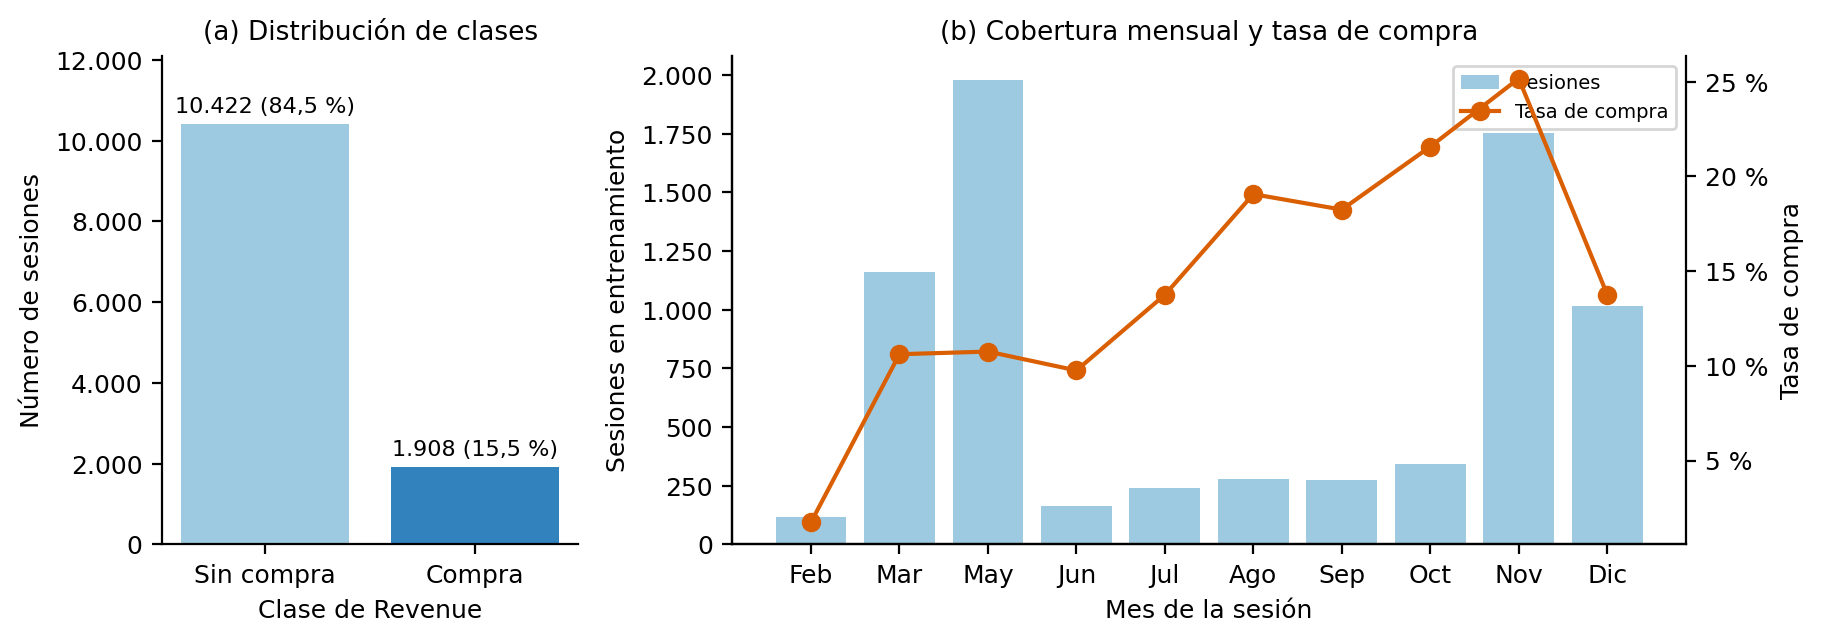

[Abrir figura: fig01_clases_cobertura.png](../informe_entregable_II_latex/figuras/fig01_clases_cobertura.png)

**Figura 2: efecto de los hiperparámetros** (`informe_entregable_II_latex/figuras/fig02_hiperparametros.png`)

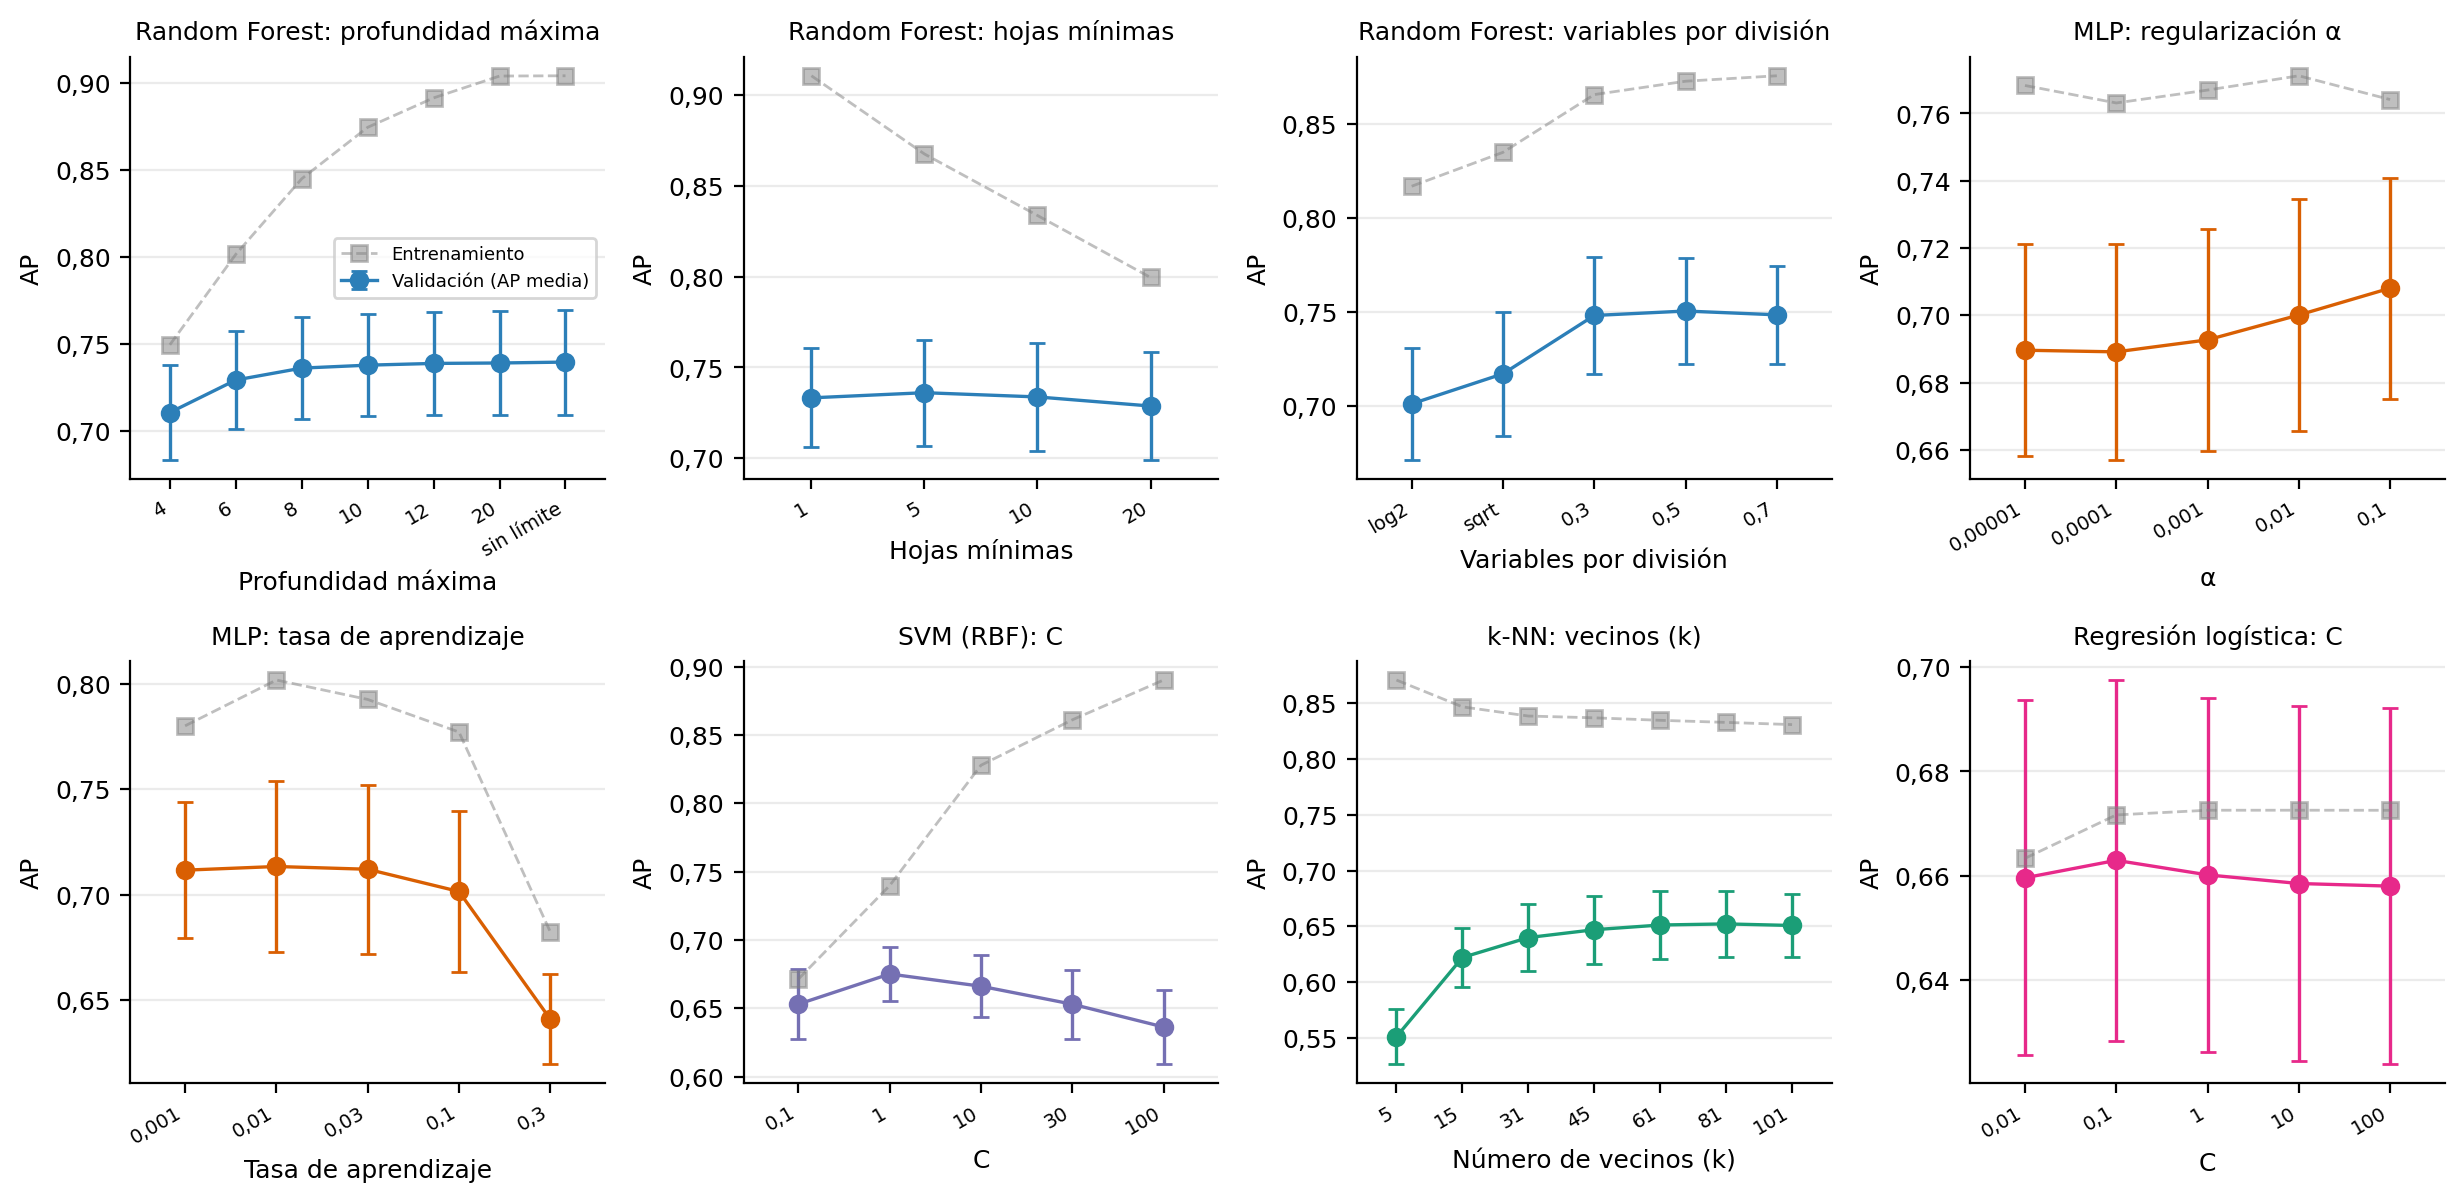

[Abrir figura: fig02_hiperparametros.png](../informe_entregable_II_latex/figuras/fig02_hiperparametros.png)

**Figura 3: curvas precisión-recall y ROC en validación** (`informe_entregable_II_latex/figuras/fig03_pr_roc_validacion.png`)

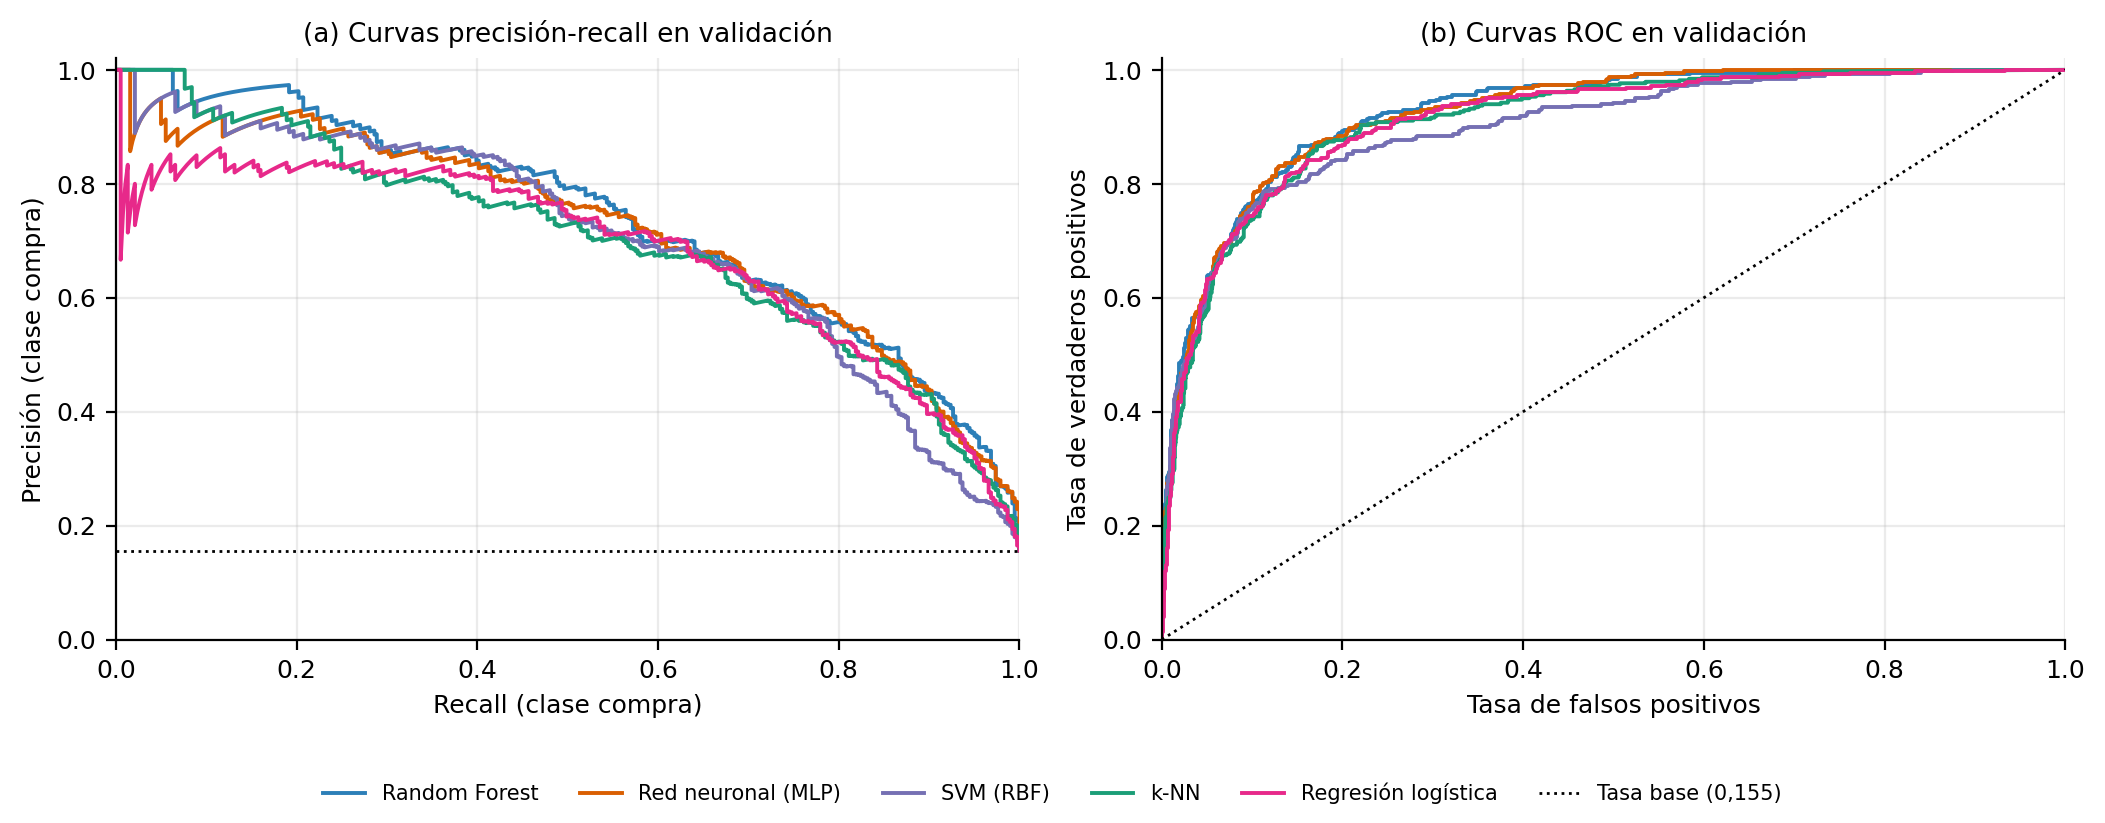

[Abrir figura: fig03_pr_roc_validacion.png](../informe_entregable_II_latex/figuras/fig03_pr_roc_validacion.png)

**Figura 4: matrices de confusión en prueba (RF y MLP)** (`informe_entregable_II_latex/figuras/fig07_matrices_confusion.png`)

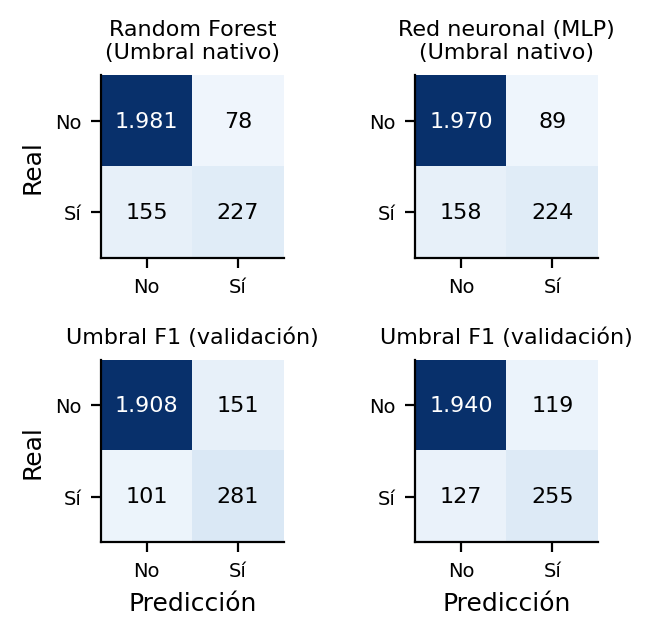

[Abrir figura: fig07_matrices_confusion.png](../informe_entregable_II_latex/figuras/fig07_matrices_confusion.png)

**Figura 5: variables con mayor AUC univariado** (`informe_entregable_II_latex/figuras/fig04_variables_auc.png`)

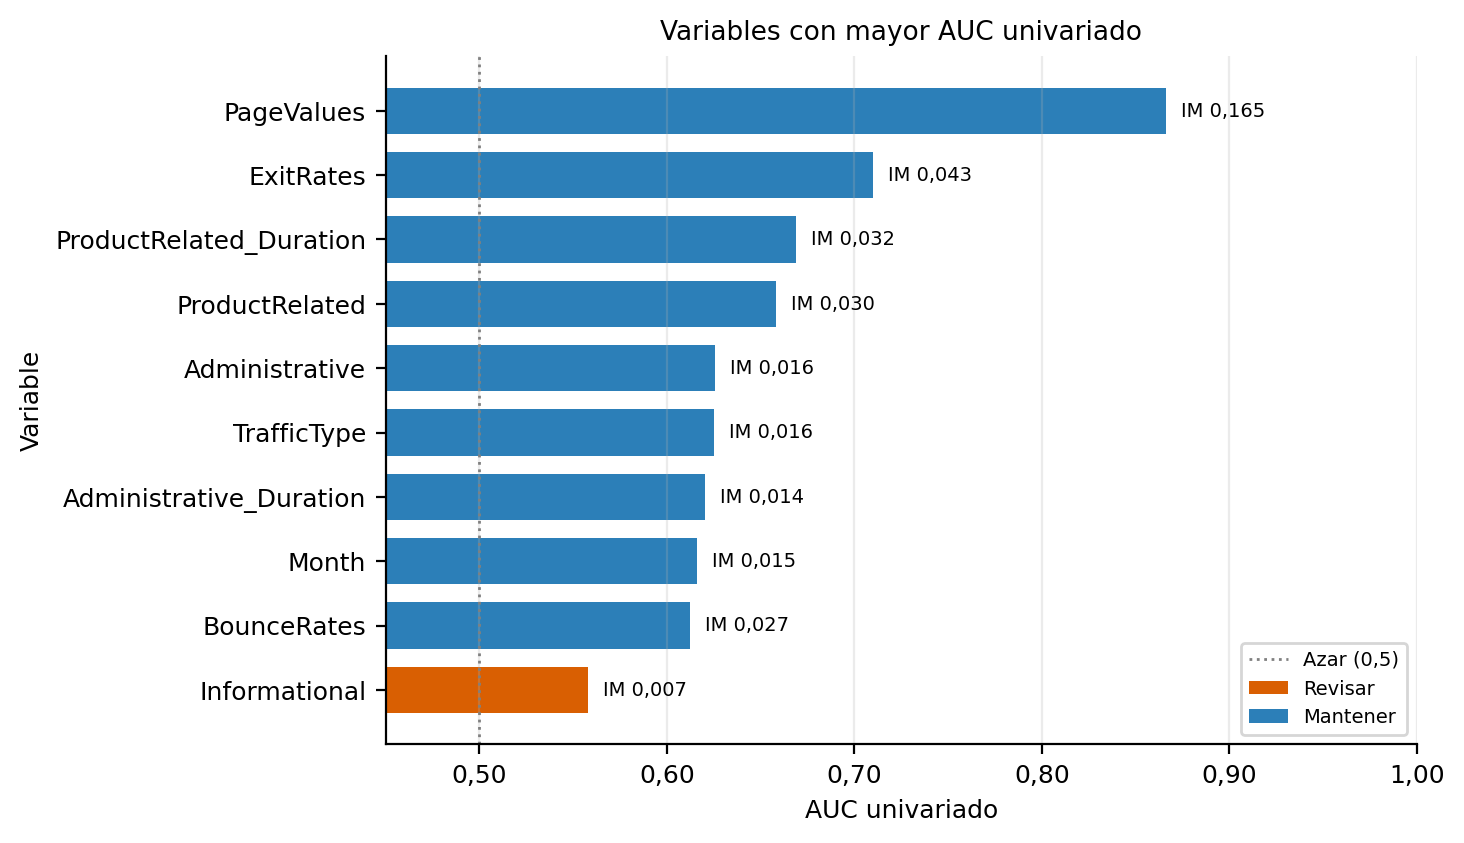

[Abrir figura: fig04_variables_auc.png](../informe_entregable_II_latex/figuras/fig04_variables_auc.png)

**Figura 6: PCA, UMAP y comparación con la base** (`informe_entregable_II_latex/figuras/fig05_reduccion.png`)

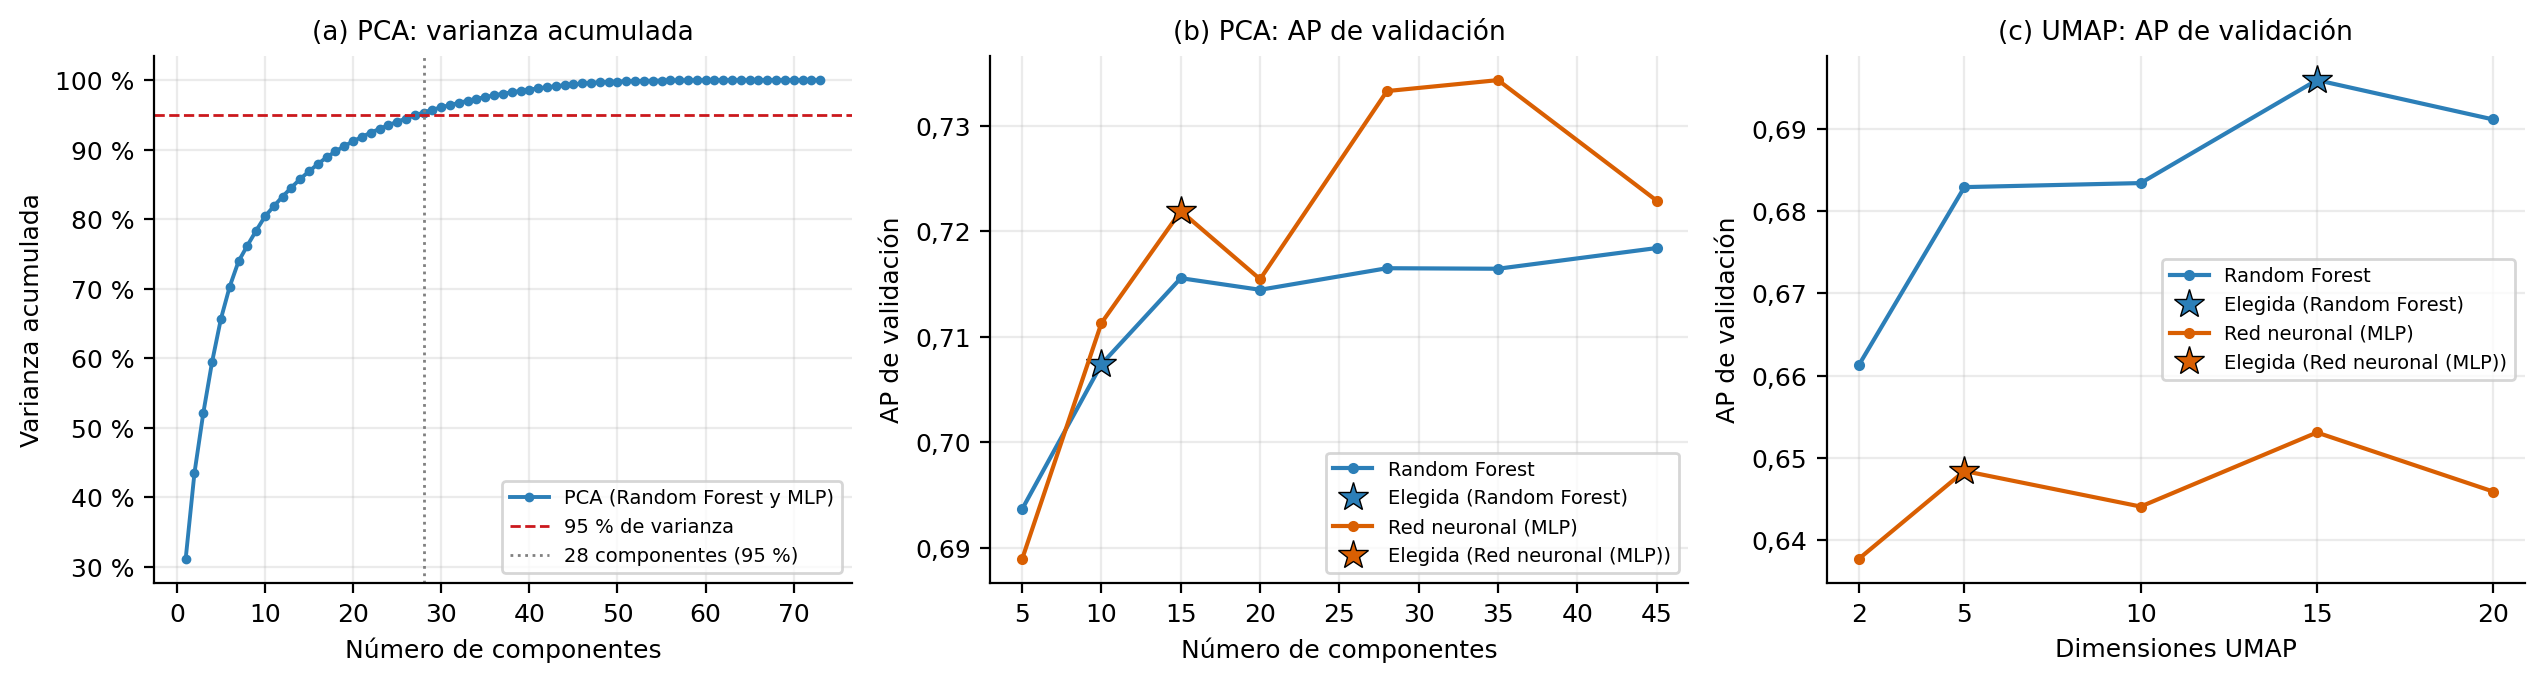

[Abrir figura: fig05_reduccion.png](../informe_entregable_II_latex/figuras/fig05_reduccion.png)

**Figura 7: proyección UMAP 2D en prueba** (`informe_entregable_II_latex/figuras/fig06_umap_2d.png`)

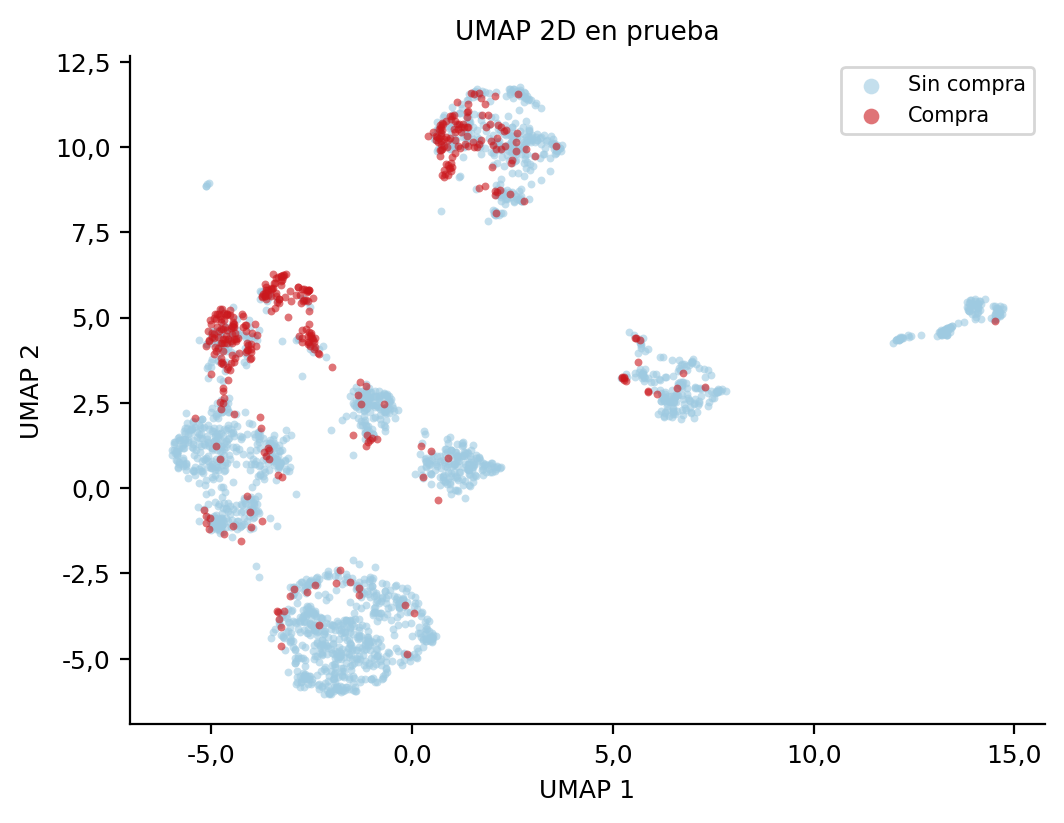

[Abrir figura: fig06_umap_2d.png](../informe_entregable_II_latex/figuras/fig06_umap_2d.png)

**AP en entrenamiento y validación** (`resultados/figuras/nb01_train_vs_validacion.png`)

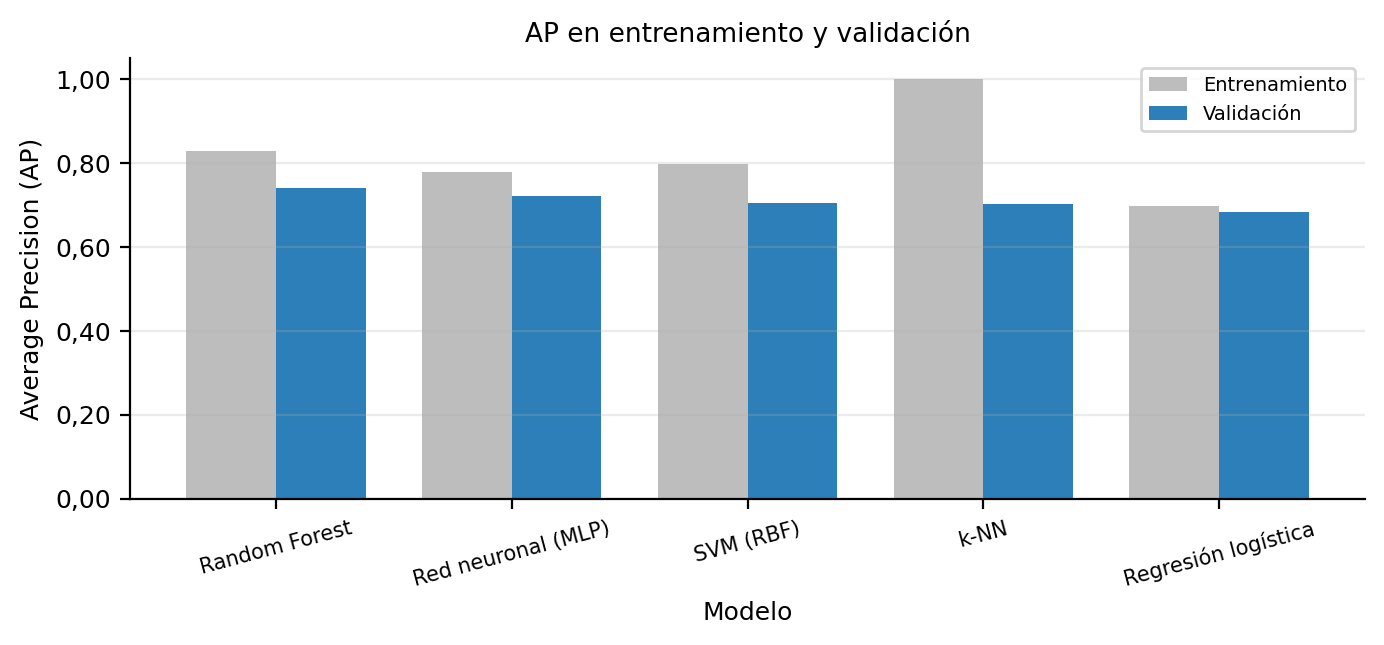

[Abrir figura: nb01_train_vs_validacion.png](../resultados/figuras/nb01_train_vs_validacion.png)

**Matrices de confusión en prueba** (`resultados/figuras/nb02_matrices_confusion_test.png`)

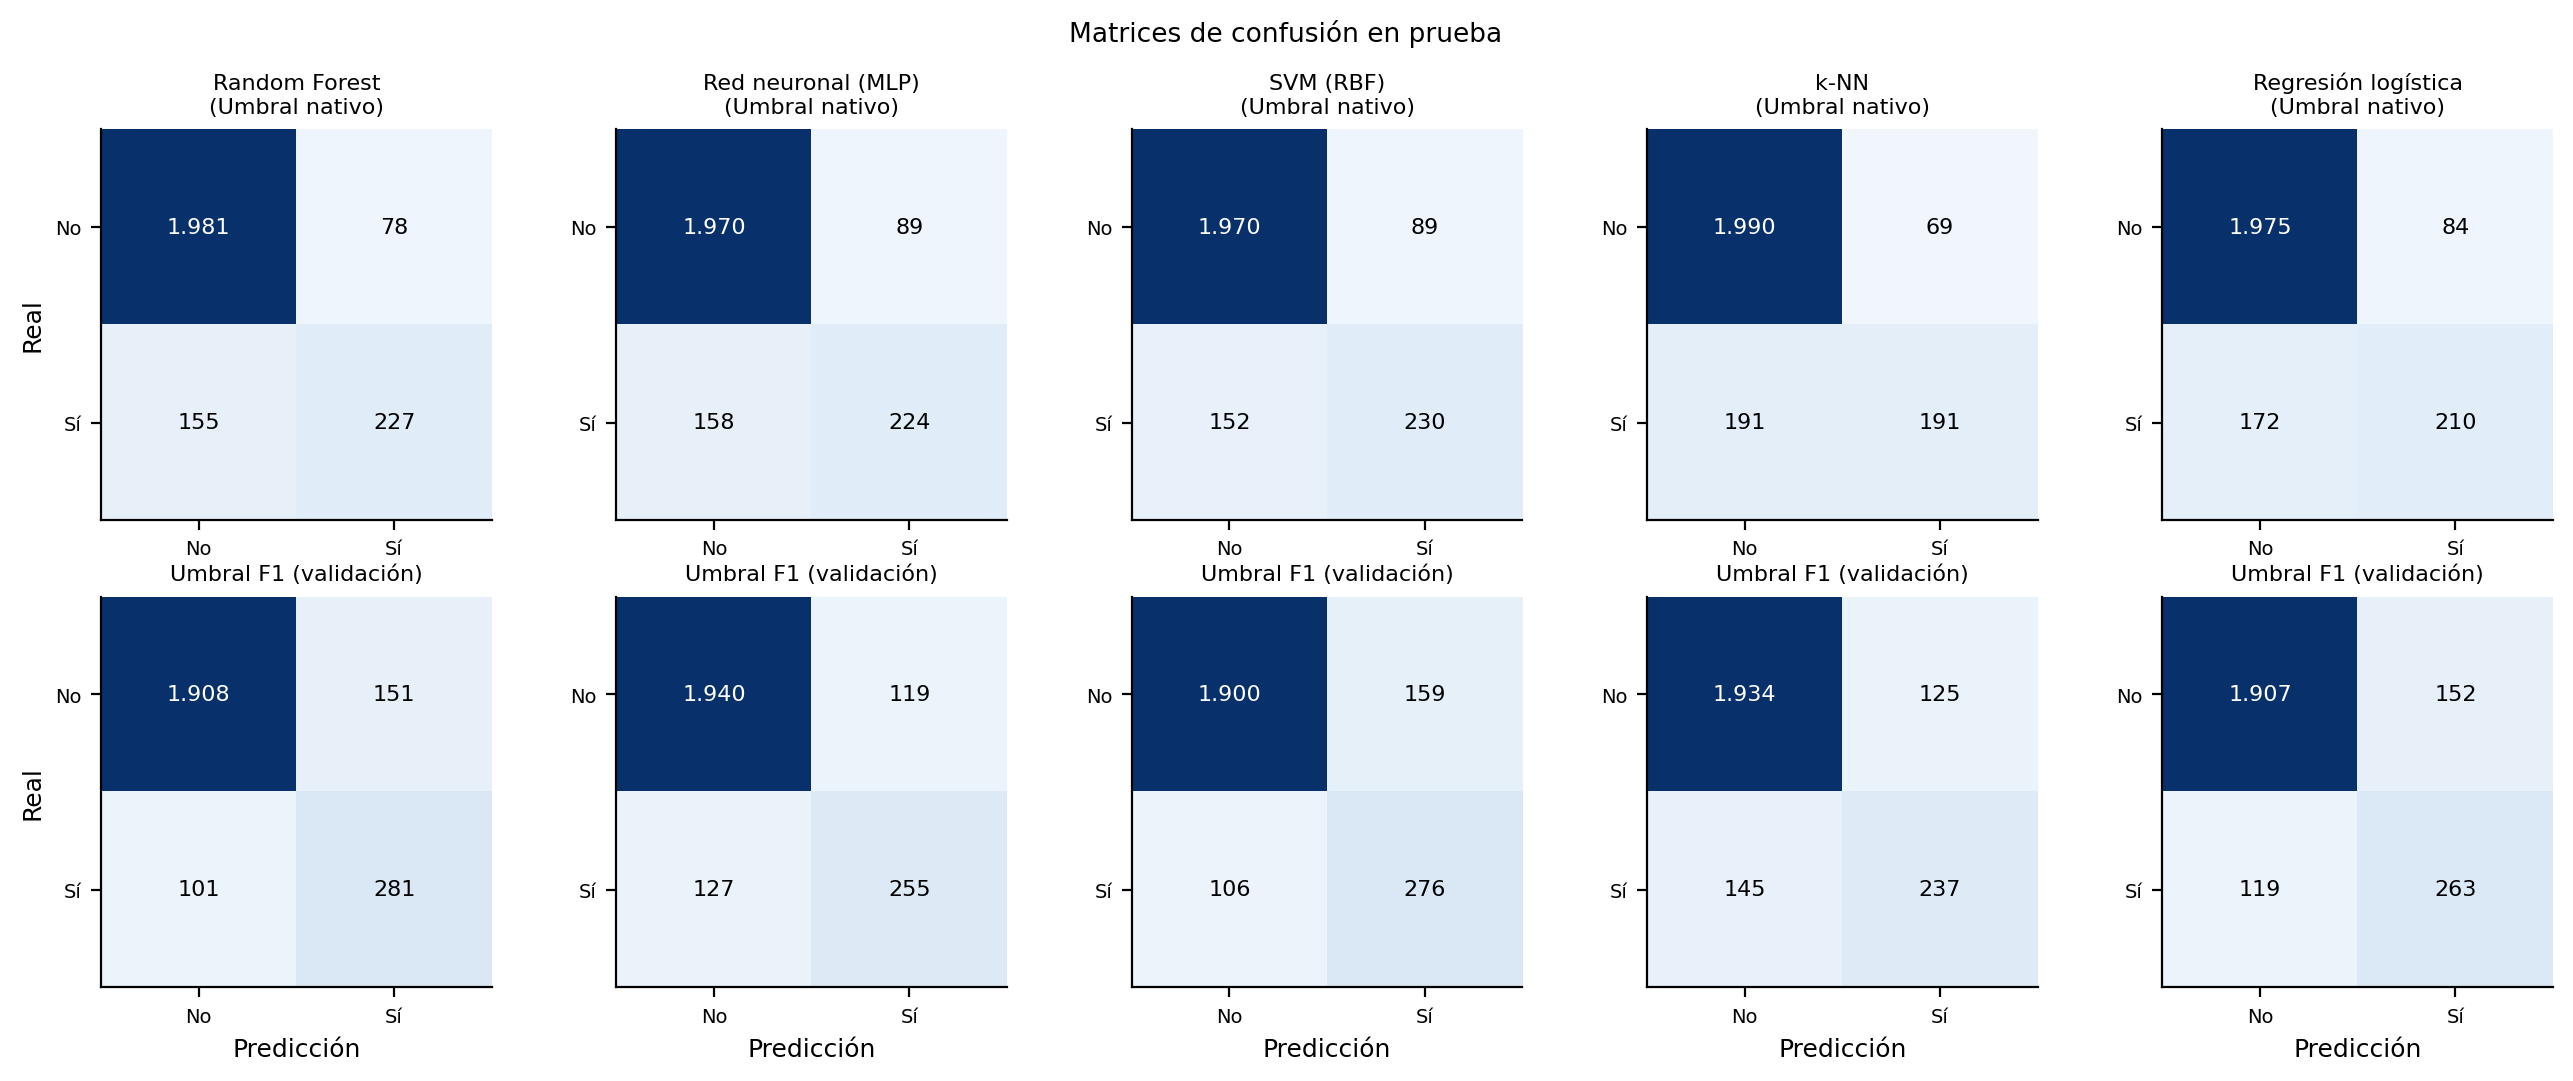

[Abrir figura: nb02_matrices_confusion_test.png](../resultados/figuras/nb02_matrices_confusion_test.png)

**AP con intervalos bootstrap** (`resultados/figuras/nb03_ap_intervalos.png`)

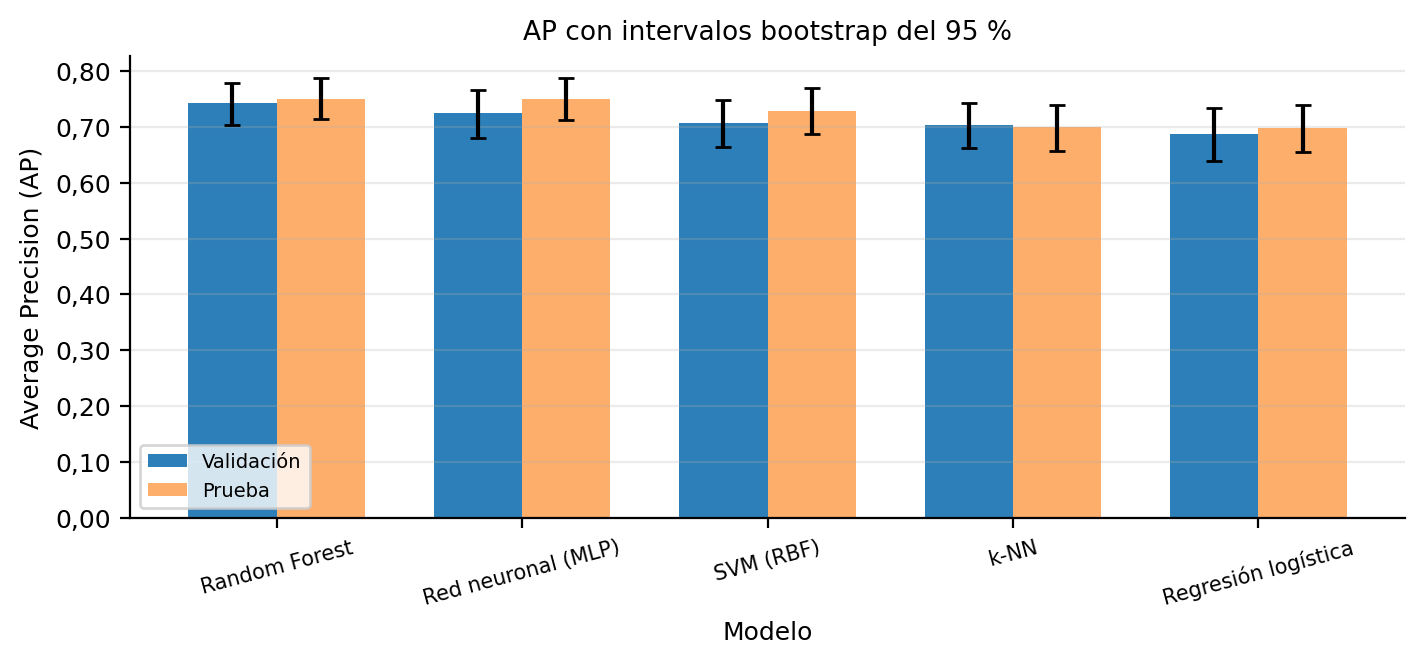

[Abrir figura: nb03_ap_intervalos.png](../resultados/figuras/nb03_ap_intervalos.png)

**Sensibilidad a PageValues** (`resultados/figuras/nb04_sensibilidad_pagevalues.png`)

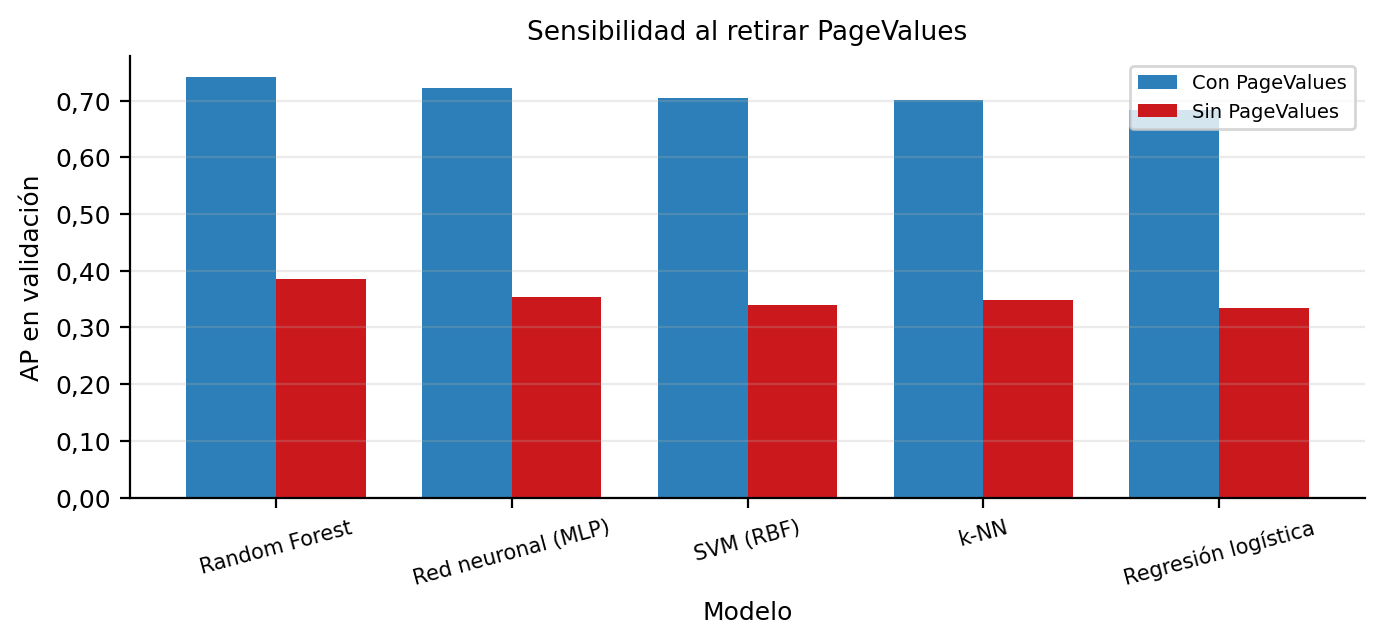

[Abrir figura: nb04_sensibilidad_pagevalues.png](../resultados/figuras/nb04_sensibilidad_pagevalues.png)

**Ablación de SpecialDay** (`resultados/figuras/nb05_ablacion_specialday.png`)

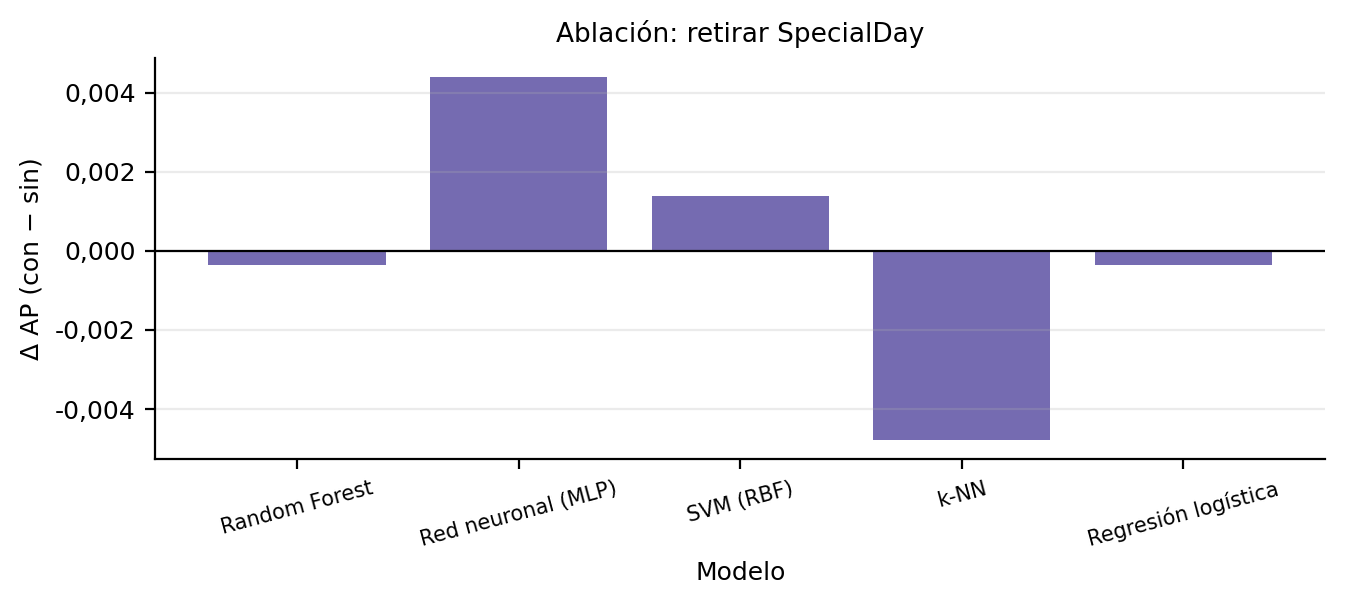

[Abrir figura: nb05_ablacion_specialday.png](../resultados/figuras/nb05_ablacion_specialday.png)

**Comparación de reducción** (`resultados/figuras/nb06_comparacion_reduccion.png`)

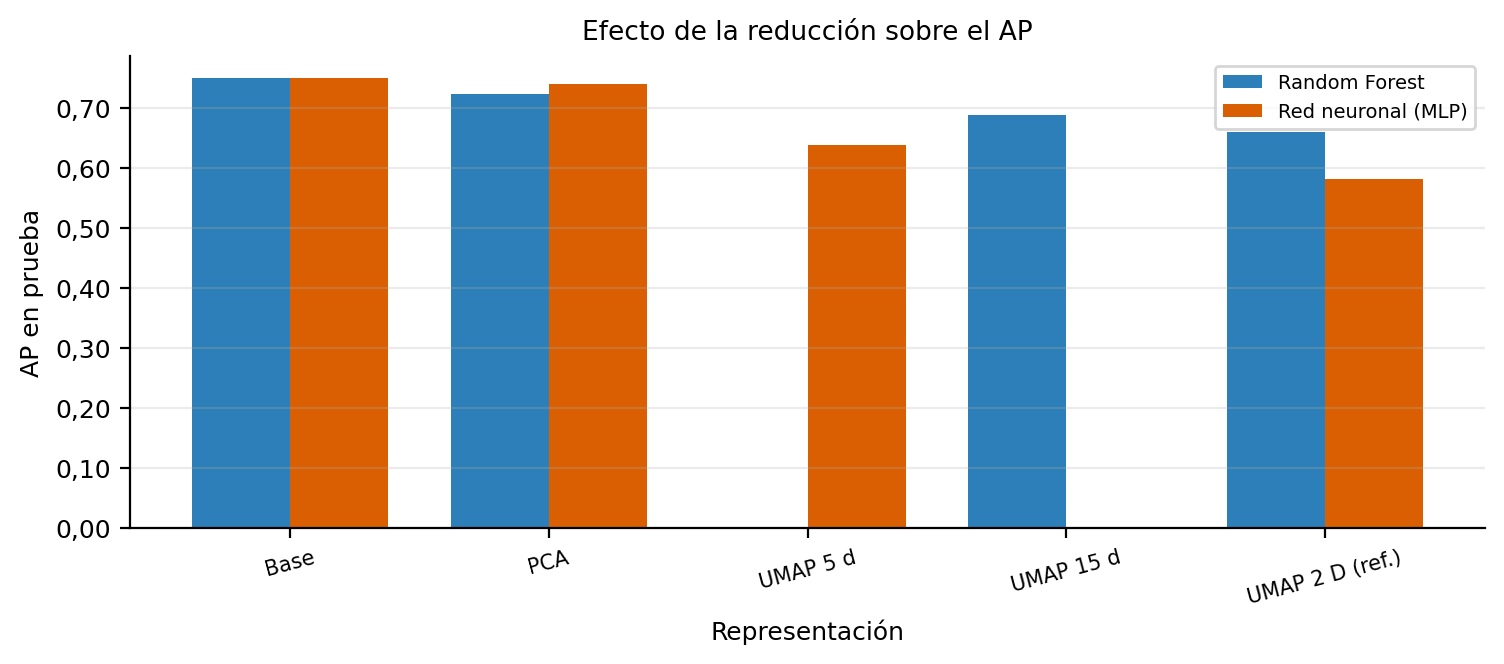

[Abrir figura: nb06_comparacion_reduccion.png](../resultados/figuras/nb06_comparacion_reduccion.png)

Figuras mostradas: 13.


In [15]:
figuras_informe = [
    ("fig01_clases_cobertura.png", "Figura 1: clases y cobertura mensual"),
    ("fig02_hiperparametros.png", "Figura 2: efecto de los hiperparámetros"),
    ("fig03_pr_roc_validacion.png", "Figura 3: curvas precisión-recall y ROC en validación"),
    ("fig07_matrices_confusion.png", "Figura 4: matrices de confusión en prueba (RF y MLP)"),
    ("fig04_variables_auc.png", "Figura 5: variables con mayor AUC univariado"),
    ("fig05_reduccion.png", "Figura 6: PCA, UMAP y comparación con la base"),
    ("fig06_umap_2d.png", "Figura 7: proyección UMAP 2D en prueba"),
]
vistas = set()
for nombre, titulo in figuras_informe:
    if mostrar_figura(nombre, titulo, carpetas=(FIG_INFORME, FIG_NOTEBOOK, RES / "figuras_informe")):
        vistas.add(nombre)

# Figuras del notebook: las seis que escribe src/figuras.py en resultados/figuras,
# las fig_nb_*.png si el generador cambia de nomenclatura y, como último recurso,
# cualquier PNG del flujo, para no ocultar figuras reales.
figuras_notebook = [
    ("nb01_train_vs_validacion.png", "AP en entrenamiento y validación"),
    ("nb02_matrices_confusion_test.png", "Matrices de confusión en prueba"),
    ("nb03_ap_intervalos.png", "AP con intervalos bootstrap"),
    ("nb04_sensibilidad_pagevalues.png", "Sensibilidad a PageValues"),
    ("nb05_ablacion_specialday.png", "Ablación de SpecialDay"),
    ("nb06_comparacion_reduccion.png", "Comparación de reducción"),
]
for nombre, titulo in figuras_notebook:
    if mostrar_figura(nombre, titulo, carpetas=(FIG_NOTEBOOK, RES / "figuras_informe")):
        vistas.add(nombre)

candidatas_nb = []
for carpeta in (FIG_NOTEBOOK, FIG_INFORME, RES / "figuras_informe"):
    if carpeta.is_dir():
        candidatas_nb.extend(sorted(carpeta.glob("fig_nb_*.png")))
for ruta in candidatas_nb:
    if ruta.name in vistas:
        continue
    mostrar_figura(
        ruta.name,
        ruta.stem.replace("_", " "),
        carpetas=(FIG_NOTEBOOK, RES / "figuras_informe", FIG_INFORME),
    )
    vistas.add(ruta.name)

for carpeta in (FIG_NOTEBOOK, RES / "figuras_informe"):
    if not carpeta.is_dir():
        continue
    for ruta in sorted(carpeta.glob("*.png")):
        if ruta.name in vistas:
            continue
        mostrar_figura(
            ruta.name,
            ruta.stem.replace("_", " "),
            carpetas=(FIG_NOTEBOOK, RES / "figuras_informe"),
        )
        vistas.add(ruta.name)

if not vistas:
    print("AVISO: no hay figuras generadas; ejecute la etapa de figuras o active RECALCULAR.")
else:
    print(f"Figuras mostradas: {len(vistas)}.")

## 13. Lectura, limitaciones y archivos leídos

Las tablas de este notebook no sustituyen al informe: son una lectura directa de los artefactos
de la ejecución. Cualquier conclusión sobre el mejor modelo, la utilidad de una variable o el
efecto de una transformación debe contrastarse con la tabla y el intervalo correspondientes.

Limitaciones que deben acompañar la lectura:

- La partición de prueba no participó en ninguna decisión de esta versión, pero sus métricas se
  conocían de una primera versión del trabajo: se leen como descriptivas y no como una evaluación
  independiente. Los intervalos bootstrap son condicionales a los modelos y a la partición fijados.
- Las cifras de Lin y Sakar et al. provienen de protocolos distintos y no se reproducen aquí.
- El modo `RECALCULAR = True` reentrena y puede sobrescribir resultados y figuras.
- Si falta un archivo, la sección lo advierte y el resto del notebook continúa.

La tabla final registra los archivos efectivamente leídos en esta ejecución, sin rutas absolutas.

In [16]:
if REGISTRO:
    trazabilidad = pd.DataFrame(REGISTRO).drop_duplicates(subset=["archivo"])
    display(Markdown(f"**Archivos leídos en esta ejecución ({len(trazabilidad)})**"))
    display(trazabilidad)
else:
    print("No se leyó ningún archivo de resultados.")

**Archivos leídos en esta ejecución (35)**

,archivo,filas,columnas
0,resultados/manifiesto.json,NaN,NaN
1,resultados/auditoria.json,NaN,NaN
2,resultados/tabla_variables.csv,18.0,9.0
3,resultados/resumen_particiones.csv,3.0,5.0
4,resultados/cobertura_mensual_train.csv,10.0,3.0
5,resultados/mejores_configuraciones.csv,5.0,12.0
6,resultados/ganador.json,NaN,NaN
7,resultados/validacion_top3.csv,15.0,12.0
8,resultados/cv_todos_los_candidatos.csv,730.0,36.0
9,resultados/combinaciones_malla.csv,5.0,2.0


## 14. Discusión y conclusiones

Random Forest ganó la regla de selección con AP de 0,7414 en validación y 0,7496 en
prueba; la MLP quedó en 0,7225 y 0,7494. Las comparaciones pareadas en prueba no detectan
diferencia entre ambas, lo que no demuestra equivalencia: la elección debe hacerse por
criterios operativos. El umbral es una decisión de negocio: con el umbral ajustado por F1
en validación, el recall de Random Forest sube de 0,594 a 0,736 a costa de precisión.
`PageValues` explica la mayor parte del desempeño y su retiro deja el AP de validación
entre 0,33 y 0,38; el modelo sirve para analizar sesiones cerradas, no para decidir
durante la sesión. Quitar las seis variables con AUC univariado menor que 0,55 no deteriora el AP, mientras
que la reducción de dimensión no mejora el resultado. La partición de prueba no participó en ninguna
decisión de esta versión, pero sus métricas se conocían de una primera versión: se leen como
descriptivas. Los intervalos bootstrap son condicionales a los modelos y predicciones fijos.